In [ ]:
m,# SETUP — Mount Google Drive + auto-detect project folder

import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install",
                "geopandas", "osmnx", "networkx", "scikit-learn",
                "scipy", "folium", "mapclassify", "--quiet"],
               capture_output=True)

from google.colab import drive
import os

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")
else:
    print("  Drive already mounted.")

FOLDER = "/content/drive/.shortcut-targets-by-id/1L3n1vOH5nkIKR6MRlSwhFCWLRVYRVUHb/DSLSC"

BIKEMI_CSV  = os.path.join(FOLDER, "bikemi_stazioni.csv")
BIKE_LANES_SHP = os.path.join(FOLDER, "bike_ciclabili_shp.zip")
INCOME_CSV = os.path.join(FOLDER, "redditi_irpef_2022.csv")

NIL_URL = (
    "https://raw.githubusercontent.com/abahgat/"
    "opendata-milano/master/geojson/quartieri.geojson"
)

print("  File check:")
for name, path in [("bikemi_stazioni.csv",   BIKEMI_CSV),
                   ("bike_ciclabili_shp.zip", BIKE_LANES_SHP),
                   ("redditi_irpef_2022.csv", INCOME_CSV)]:
    ok = os.path.exists(path)
    print(f"    {'✓' if ok else '✗'} {name}")

print("\nSetup complete.")


  Drive already mounted.
  File check:
    ✓ bikemi_stazioni.csv
    ✓ bike_ciclabili_shp.zip
    ✓ redditi_irpef_2022.csv

Setup complete.


TEMPORAL EDA — BikeMi and the Cycling Network
  BikeMi stations with known year: 323
  Segments with completion year: 4013
  BikeMi period: 2008–2021


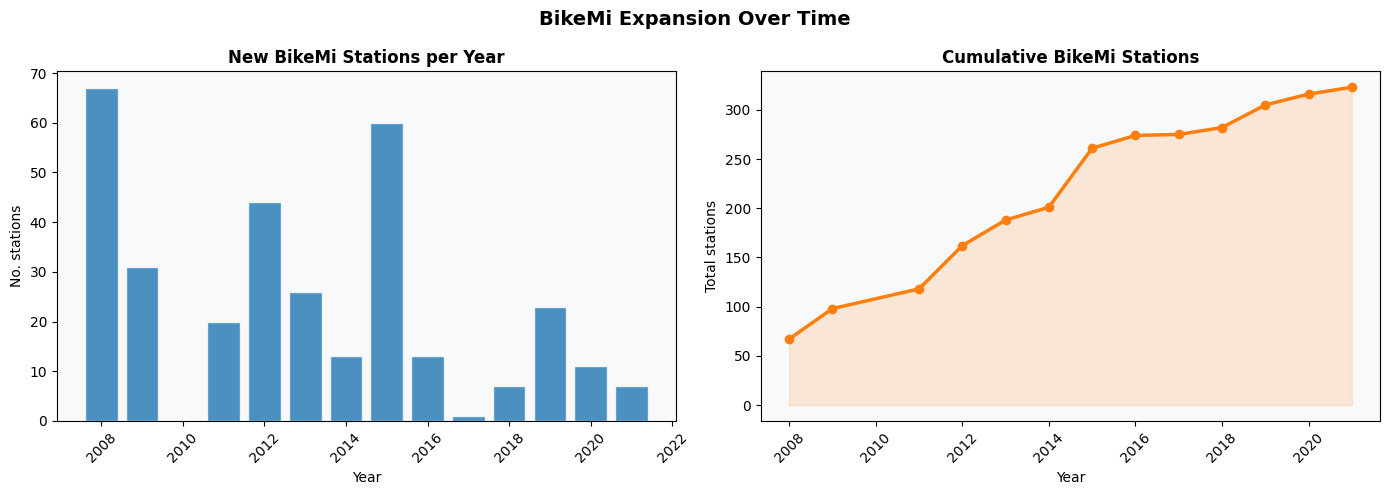

  Saved: 00a_bikemi_temporal.png


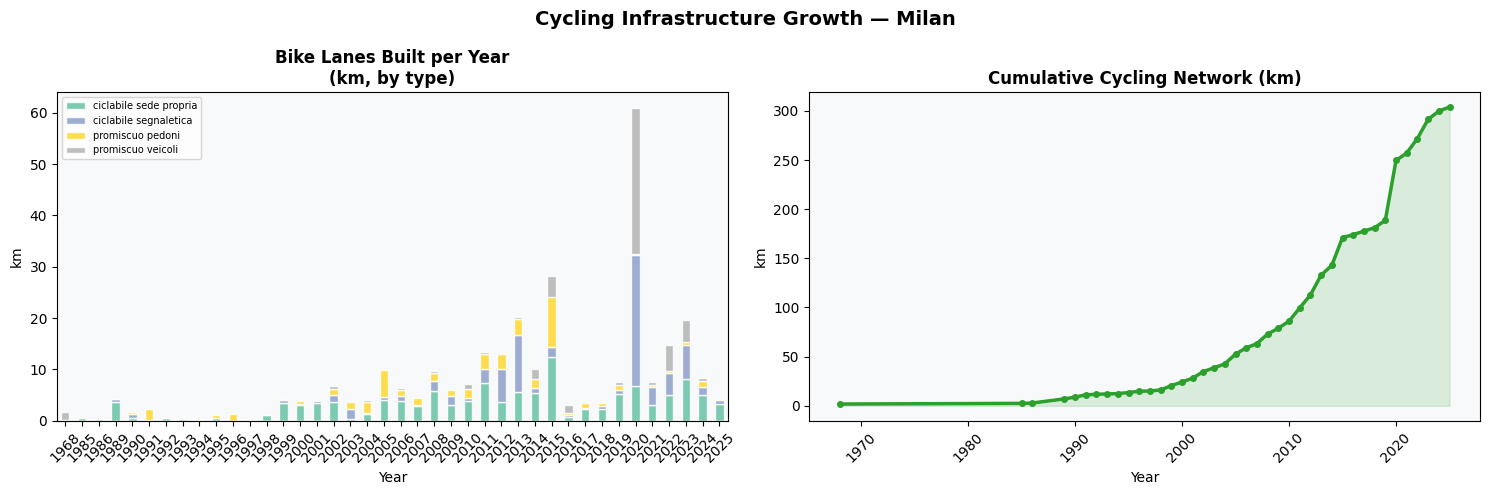

  Saved: 00b_lanes_temporal.png


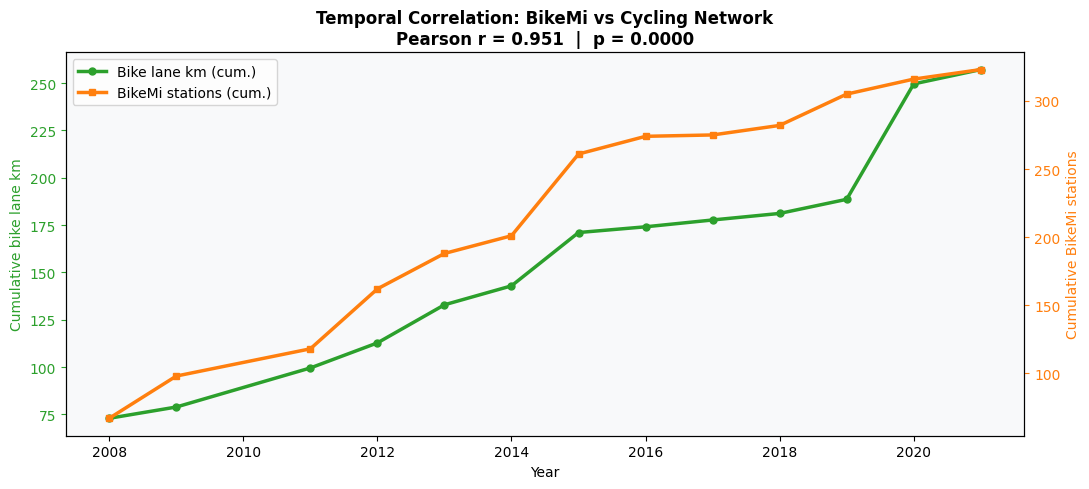


  Cumulative BikeMi–lanes correlation:
    r = 0.951
    p = 0.0000
    Significance: ***

  Saved: 00c_temporal_correlation.png


In [ ]:
# EDA: growth of BikeMi and the cycling network over time
# Spatio-temporal correlation analysis
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats as scipy_stats

print("=" * 55)
print("TEMPORAL EDA — BikeMi and the Cycling Network")
print("=" * 55)

# load data
_bikemi_df = pd.read_csv(BIKEMI_CSV, sep=";", encoding="utf-8")
_bikemi_df = _bikemi_df.rename(columns={"anno": "year", "stalli": "stalls"})
_bikemi_df["year"]   = pd.to_numeric(_bikemi_df["year"],   errors="coerce")
_bikemi_df["stalls"] = pd.to_numeric(_bikemi_df["stalls"], errors="coerce")

_bike_lanes = gpd.read_file(f"zip://{BIKE_LANES_SHP}").to_crs("EPSG:32632")
_bike_lanes = _bike_lanes.rename(columns={"fine_lavor": "end_work", "tipologia": "typology"})
_bike_lanes["end_work"] = pd.to_numeric(
    _bike_lanes["end_work"], errors="coerce")
_bike_lanes["len_m"] = _bike_lanes.geometry.length

# BikeMi by year
by_year = (
    _bikemi_df.dropna(subset=["year"])
    .groupby("year")
    .agg(n_stations=("id_amat", "count"),
         n_stalls=("stalls", "sum"))
    .reset_index()
)
by_year["cum_stations"] = by_year["n_stations"].cumsum()

# bike lanes by year
_built = _bike_lanes[_bike_lanes["end_work"] > 0].copy()
yearly_pivot = (
    _built.groupby(["end_work", "typology"])["len_m"]
    .sum().reset_index()
    .assign(len_km=lambda x: x["len_m"] / 1000)
    .pivot_table(index="end_work", columns="typology",
                 values="len_km", aggfunc="sum", fill_value=0)
)
cum_lanes = (
    _built.groupby("end_work")["len_m"]
    .sum().sort_index().cumsum() / 1000
)

print(f"  BikeMi stations with known year: "
      f"{_bikemi_df['year'].notna().sum()}")
print(f"  Segments with completion year: {len(_built)}")
print(f"  BikeMi period: "
      f"{int(by_year['year'].min())}–{int(by_year['year'].max())}")

# figure 1: BikeMi growth
BLUE = "#1f77b4"
ORANGE = "#ff7f0e"
GREEN = "#2ca02c"
RED = "#d62728"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(by_year["year"], by_year["n_stations"],
            color=BLUE, alpha=0.8, edgecolor="white")
axes[0].set_title("New BikeMi Stations per Year",
                  fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("No. stations")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_facecolor("#f8f9fa")

axes[1].plot(by_year["year"], by_year["cum_stations"],
             marker="o", color=ORANGE, linewidth=2.5, markersize=6)
axes[1].fill_between(by_year["year"], by_year["cum_stations"],
                     alpha=0.15, color=ORANGE)
axes[1].set_title("Cumulative BikeMi Stations",
                  fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total stations")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_facecolor("#f8f9fa")

plt.suptitle("BikeMi Expansion Over Time",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("00a_bikemi_temporal.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 00a_bikemi_temporal.png")

# figure 2: bike lane growth by type
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

yearly_pivot.plot(kind="bar", stacked=True, ax=axes[0],
                  colormap="Set2", alpha=0.85, edgecolor="white")
axes[0].set_title("Bike Lanes Built per Year\n(km, by type)",
                  fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("km")
axes[0].legend(loc="upper left", fontsize=7)
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_facecolor("#f8f9fa")

axes[1].plot(cum_lanes.index, cum_lanes.values,
             color=GREEN, linewidth=2.5, marker="o", markersize=4)
axes[1].fill_between(cum_lanes.index, cum_lanes.values,
                     alpha=0.15, color=GREEN)
axes[1].set_title("Cumulative Cycling Network (km)",
                  fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("km")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_facecolor("#f8f9fa")

plt.suptitle("Cycling Infrastructure Growth — Milan",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("00b_lanes_temporal.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 00b_lanes_temporal.png")

# figure 3: spatio-temporal correlation
common_years = sorted(
    set(cum_lanes.index) & set(by_year["year"])
)
df_corr = pd.DataFrame({
    "year":    common_years,
    "cum_km":  [cum_lanes[y] for y in common_years],
    "cum_st":  [by_year.set_index("year")["cum_stations"][y]
                for y in common_years],
})
r_temp, p_temp = scipy_stats.pearsonr(
    df_corr["cum_km"], df_corr["cum_st"]
)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

ax1.plot(df_corr["year"], df_corr["cum_km"],
         color=GREEN, linewidth=2.5, marker="o", markersize=5,
         label="Bike lane km (cum.)")
ax2.plot(df_corr["year"], df_corr["cum_st"],
         color=ORANGE, linewidth=2.5, marker="s", markersize=5,
         label="BikeMi stations (cum.)")

ax1.set_xlabel("Year")
ax1.set_ylabel("Cumulative bike lane km", color=GREEN)
ax2.set_ylabel("Cumulative BikeMi stations", color=ORANGE)
ax1.tick_params(axis="y", colors=GREEN)
ax2.tick_params(axis="y", colors=ORANGE)

lines1, labs1 = ax1.get_legend_handles_labels()
lines2, labs2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labs1 + labs2, loc="upper left")

ax1.set_title(
    f"Temporal Correlation: BikeMi vs Cycling Network\n"
    f"Pearson r = {r_temp:.3f}  |  p = {p_temp:.4f}",
    fontweight="bold"
)
ax1.set_facecolor("#f8f9fa")
plt.tight_layout()
plt.savefig("00c_temporal_correlation.png",
            dpi=150, bbox_inches="tight")
plt.show()

print(f"\n  Cumulative BikeMi–lanes correlation:")
print(f"    r = {r_temp:.3f}")
print(f"    p = {p_temp:.4f}")
sig = ("***" if p_temp < 0.001 else "**" if p_temp < 0.01
       else "*" if p_temp < 0.05 else "n.s.")
print(f"    Significance: {sig}")
print(f"\n  Saved: 00c_temporal_correlation.png")


del _bikemi_df, _bike_lanes, _built


DATA LOADING...

Loading BikeMi stations...
  Stations loaded: 325

Loading bike lanes...
  Bike lane segments loaded: 4154

Loading NIL from GitHub...
  NIL (neighbourhoods) loaded: 88

BASE MAP


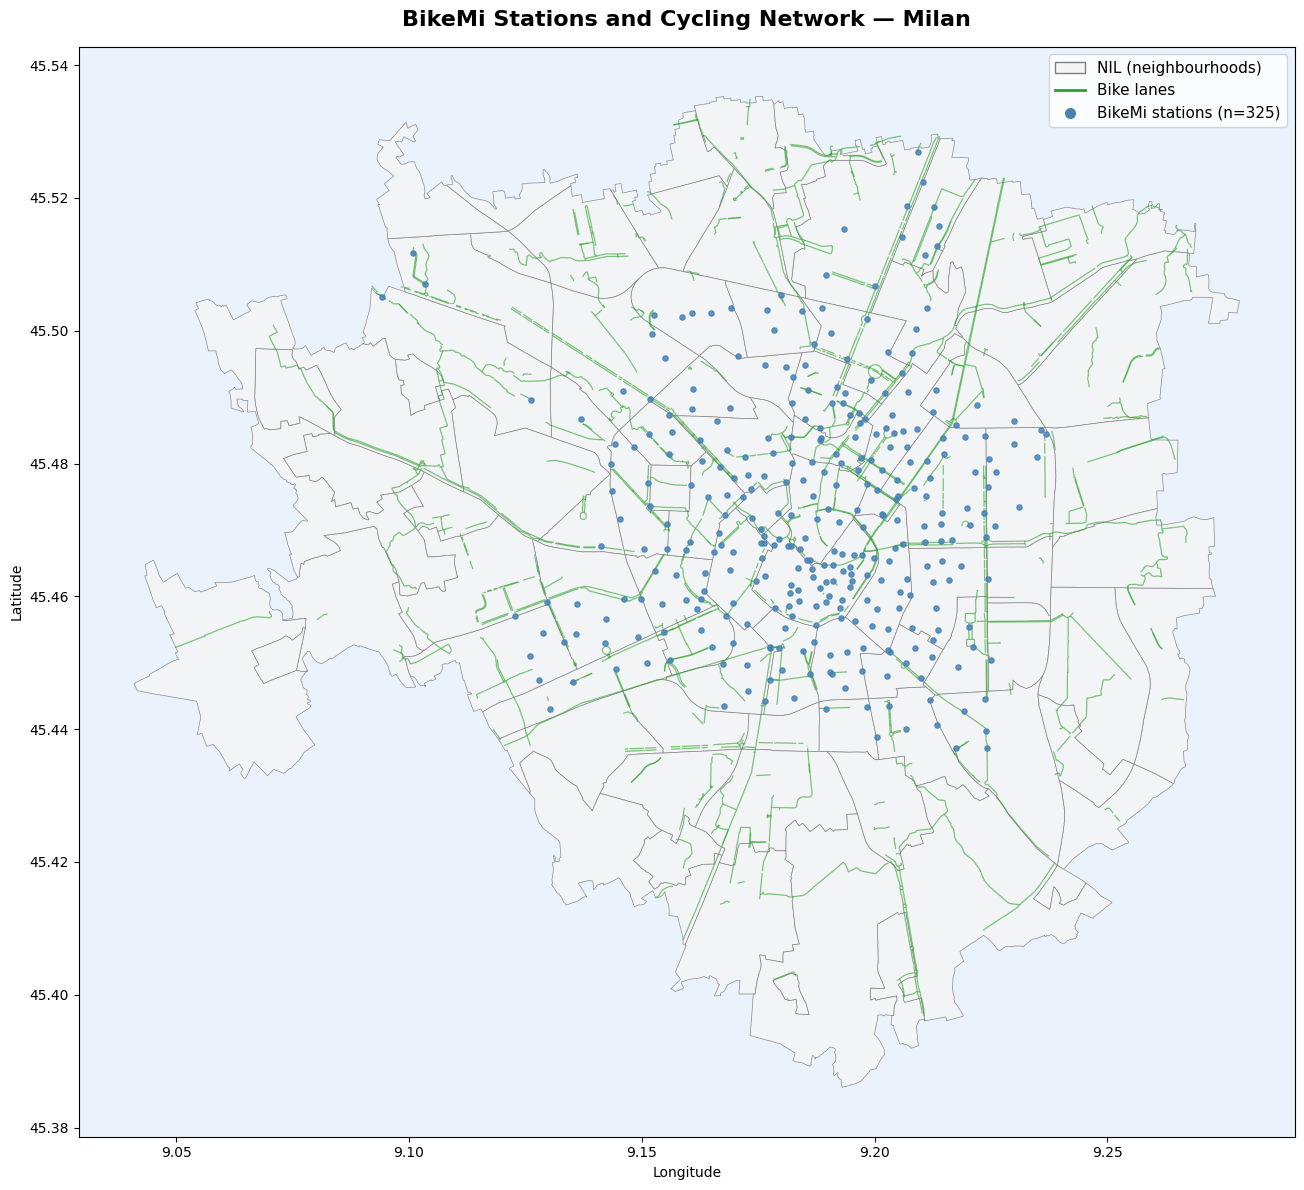

  Saved: 01_base_map.png

SPATIAL JOIN — stations per NIL

  Top 10 NIL by number of BikeMi stations:
                   NIL  n_stations
                 DUOMO          39
BUENOS AIRES - VENEZIA          23
             GUASTALLA          16
                 BRERA          14
                 SARPI          13
                 ISOLA          12
              CENTRALE          12
                PAGANO          10
          CITTA' STUDI           9
            XXII MARZO           9

  NIL with no BikeMi station: 41

BIKE LANE LENGTH PER NIL

  Total cycling network length: 332.8 km

  Top 10 NIL by km of bike lanes:
                   NIL  km_bike_lanes
   PARCO DELLE ABBAZIE          11.95
BUENOS AIRES - VENEZIA          10.92
 NIGUARDA - CA' GRANDA          10.74
  PARCO BOSCO IN CITTÀ           9.06
               STADERA           8.74
               ADRIANO           8.22
          VILLAPIZZONE           8.22
           VIALE MONZA           7.74
          FORZE ARMATE           7

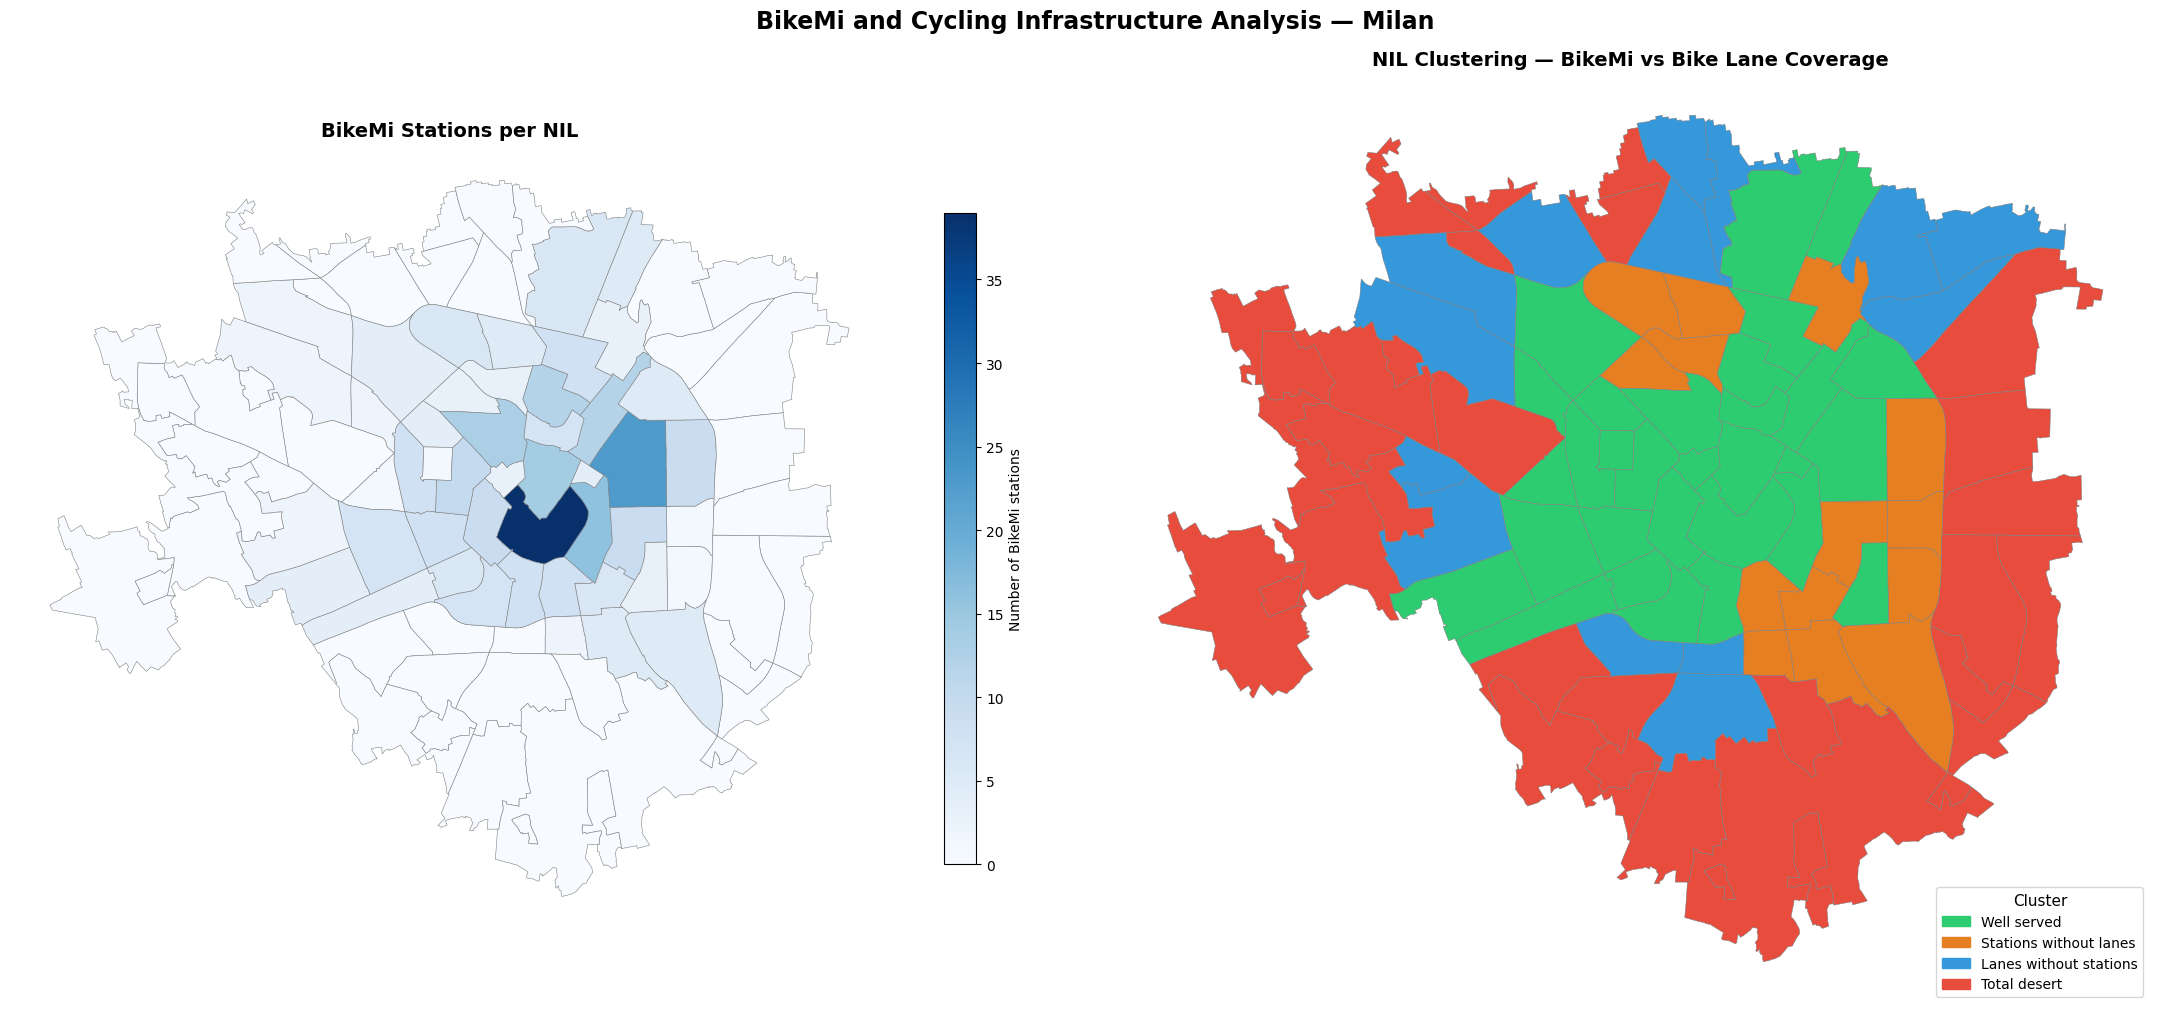

  Saved: 02_choropleth_bikemi.png


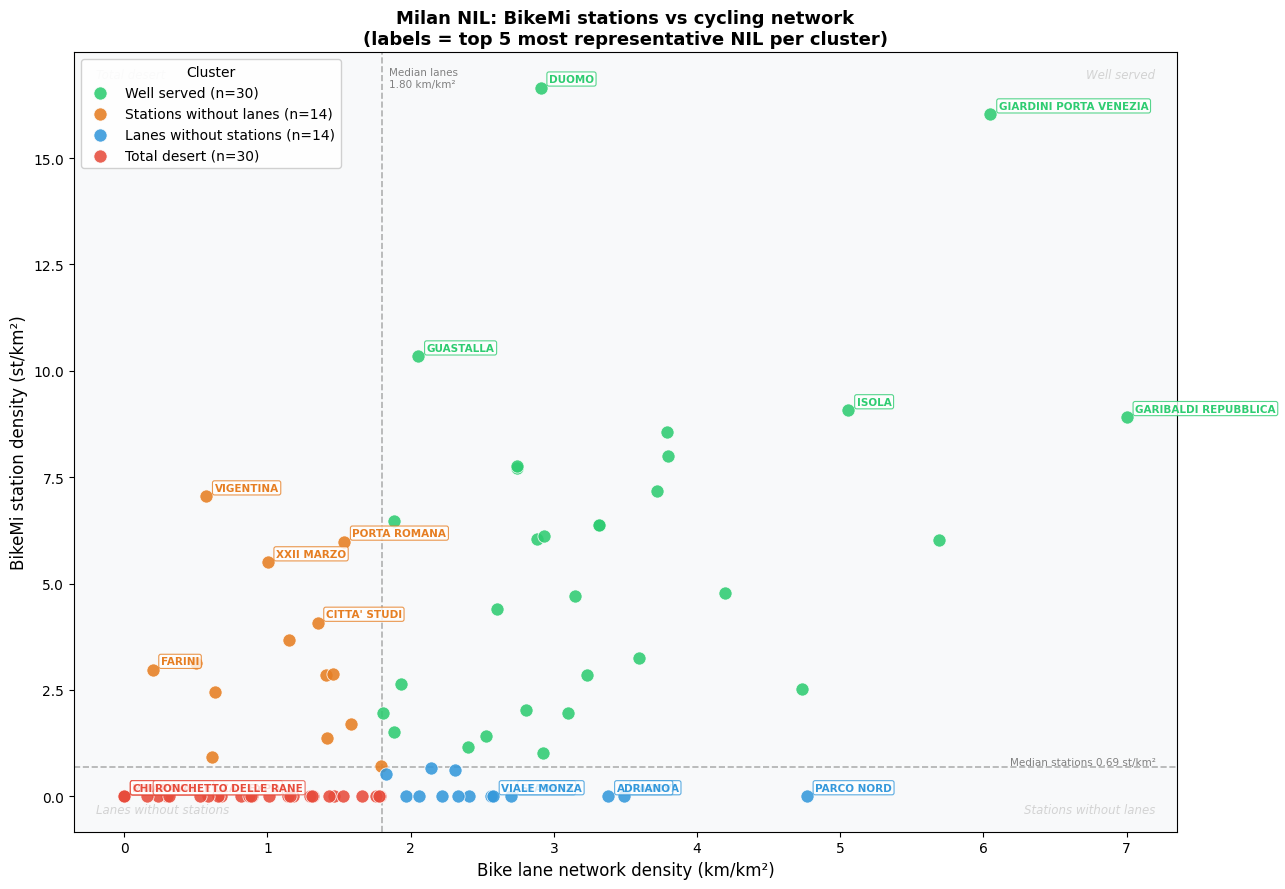

  Saved: 03_scatter_nil.png

  Aggregated data saved to: nil_aggregated_analysis.csv

SUMMARY
  Total BikeMi stations: 325
  Total bike lane segments: 4154
  Cycling network length:          332.8 km
  NIL analysed: 88
  NIL with no BikeMi station:      41
  NIL with no bike lanes:          4

  Cluster 'Total desert':          30 NIL
  Cluster 'Well served':           30 NIL


In [ ]:
# data loading, base maps, NIL clustering
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# DATA LOADING
print("=" * 55)
print("DATA LOADING...")
print("=" * 55)

# BikeMi
print("\nLoading BikeMi stations...")
bikemi_df = pd.read_csv(BIKEMI_CSV, sep=";", encoding="utf-8")
bikemi_df = bikemi_df.rename(columns={"anno": "year", "stalli": "stalls"})
bikemi_gdf = gpd.GeoDataFrame(
    bikemi_df,
    geometry=gpd.points_from_xy(
        bikemi_df["LONG_X_4326"], bikemi_df["LAT_Y_4326"]
    ),
    crs="EPSG:4326"
)
print(f"  Stations loaded: {len(bikemi_gdf)}")

# bike lanes
print("\nLoading bike lanes...")
bike_lanes_gdf = gpd.read_file(f"zip://{BIKE_LANES_SHP}")
bike_lanes_gdf = bike_lanes_gdf.to_crs("EPSG:4326")
print(f"  Bike lane segments loaded: {len(bike_lanes_gdf)}")

# NIL
print("\nLoading NIL from GitHub...")
nil_gdf = gpd.read_file(NIL_URL)
nil_gdf = nil_gdf.to_crs("EPSG:4326")
print(f"  NIL (neighbourhoods) loaded: {len(nil_gdf)}")

# BASE MAP
print("\n" + "=" * 55)
print("BASE MAP")
print("=" * 55)

fig, ax = plt.subplots(figsize=(14, 12))
nil_gdf.plot(ax=ax, color="whitesmoke", edgecolor="gray",
             linewidth=0.5, alpha=0.9)
bike_lanes_gdf.plot(ax=ax, color="#2ca02c", linewidth=0.9, alpha=0.6)
bikemi_gdf.plot(ax=ax, color="steelblue", markersize=14,
                alpha=0.85, marker="o", zorder=5)

ax.set_title("BikeMi Stations and Cycling Network — Milan",
             fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_facecolor("#eaf2fb")

legend_elements = [
    mpatches.Patch(facecolor="whitesmoke", edgecolor="gray",
                   label="NIL (neighbourhoods)"),
    plt.Line2D([0], [0], color="#2ca02c", lw=2, label="Bike lanes"),
    plt.Line2D([0], [0], marker="o", color="w",
               markerfacecolor="steelblue", markersize=9,
               label=f"BikeMi stations (n={len(bikemi_gdf)})"),
]
ax.legend(handles=legend_elements, loc="upper right", fontsize=11)
plt.tight_layout()
plt.savefig("01_base_map.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 01_base_map.png")

# SPATIAL JOIN — BikeMi stations per NIL
print("\n" + "=" * 55)
print("SPATIAL JOIN — stations per NIL")
print("=" * 55)

bikemi_in_nil = gpd.sjoin(
    bikemi_gdf, nil_gdf[["NIL", "geometry"]],
    how="left", predicate="within"
)
stations_per_nil = (
    bikemi_in_nil.groupby("NIL").size().reset_index(name="n_stations")
)
nil_analysis = nil_gdf.merge(stations_per_nil, on="NIL", how="left")
nil_analysis["n_stations"] = nil_analysis["n_stations"].fillna(0).astype(int)

print(f"\n  Top 10 NIL by number of BikeMi stations:")
print(
    nil_analysis[["NIL", "n_stations"]]
    .sort_values("n_stations", ascending=False)
    .head(10).to_string(index=False)
)
nil_no_stations = nil_analysis[nil_analysis["n_stations"] == 0]
print(f"\n  NIL with no BikeMi station: {len(nil_no_stations)}")

# BIKE LANE LENGTH PER NIL
print("\n" + "=" * 55)
print("BIKE LANE LENGTH PER NIL")
print("=" * 55)

nil_utm   = nil_gdf.to_crs("EPSG:32632")
lanes_utm = bike_lanes_gdf.to_crs("EPSG:32632")

lanes_in_nil = gpd.overlay(lanes_utm, nil_utm[["NIL", "geometry"]],
                            how="intersection")
lanes_in_nil["len_m"] = lanes_in_nil.geometry.length
km_per_nil = (
    lanes_in_nil.groupby("NIL")["len_m"].sum().reset_index()
)
km_per_nil["km_bike_lanes"] = km_per_nil["len_m"] / 1000
nil_analysis = nil_analysis.merge(
    km_per_nil[["NIL", "km_bike_lanes"]], on="NIL", how="left"
)
nil_analysis["km_bike_lanes"] = nil_analysis["km_bike_lanes"].fillna(0).round(2)

print(f"\n  Total cycling network length: "
      f"{nil_analysis['km_bike_lanes'].sum():.1f} km")
print("\n  Top 10 NIL by km of bike lanes:")
print(
    nil_analysis[["NIL", "km_bike_lanes"]]
    .sort_values("km_bike_lanes", ascending=False)
    .head(10).to_string(index=False)
)

# COVERAGE INDEX + NIL AREA
print("\n" + "=" * 55)
print("COVERAGE INDEX")
print("=" * 55)

nil_utm_area = nil_gdf.to_crs("EPSG:32632").copy()
nil_utm_area["area_km2"] = nil_utm_area.geometry.area / 1e6
nil_analysis = nil_analysis.merge(
    nil_utm_area[["NIL", "area_km2"]], on="NIL", how="left"
)
nil_analysis["station_density"]  = (nil_analysis["n_stations"]
                                     / nil_analysis["area_km2"]).round(3)
nil_analysis["lane_density"] = (nil_analysis["km_bike_lanes"]
                                     / nil_analysis["area_km2"]).round(3)

# NIL CLUSTERING
print("\n" + "=" * 55)
print("NIL CLUSTERING — 4 types")
print("=" * 55)

med_s = nil_analysis["station_density"].median()
med_c = nil_analysis["lane_density"].median()
print(f"  Median station density:   {med_s:.3f} st/km²")
print(f"  Median bike lane density: {med_c:.3f} km/km²")

def classify(row):
    high_s = row["station_density"]  >= med_s
    high_c = row["lane_density"] >= med_c
    if high_s and high_c:return "Well served"
    elif high_s and not high_c: return "Stations without lanes"
    elif not high_s and high_c: return "Lanes without stations"
    else: return "Total desert"

nil_analysis["cluster"] = nil_analysis.apply(classify, axis=1)
print("\n  Cluster distribution:")
print(nil_analysis["cluster"].value_counts().to_string())

# CHOROPLETH — stations + cluster
print("\n" + "=" * 55)
print("CHOROPLETH MAPS")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

nil_analysis.plot(
    ax=axes[0], column="n_stations", cmap="Blues", legend=True,
    legend_kwds={"label": "Number of BikeMi stations", "shrink": 0.7},
    edgecolor="gray", linewidth=0.4,
    missing_kwds={"color": "lightgrey"},
)
axes[0].set_title("BikeMi Stations per NIL", fontsize=14, fontweight="bold")
axes[0].set_facecolor("#eaf2fb")
axes[0].axis("off")

cluster_colors = {
    "Well served":              "#2ecc71",
    "Stations without lanes":   "#e67e22",
    "Lanes without stations":   "#3498db",
    "Total desert":             "#e74c3c",
}
nil_analysis["color"] = nil_analysis["cluster"].map(cluster_colors)
nil_analysis.plot(
    ax=axes[1], color=nil_analysis["color"],
    edgecolor="gray", linewidth=0.4,
)
axes[1].set_title("NIL Clustering — BikeMi vs Bike Lane Coverage",
                  fontsize=14, fontweight="bold")
axes[1].set_facecolor("#eaf2fb")
axes[1].axis("off")

patch_list = [mpatches.Patch(color=v, label=k)
              for k, v in cluster_colors.items()]
axes[1].legend(handles=patch_list, loc="lower right",
               fontsize=10, title="Cluster", title_fontsize=11)

plt.suptitle("BikeMi and Cycling Infrastructure Analysis — Milan",
             fontsize=17, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("02_choropleth_bikemi.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 02_choropleth_bikemi.png")

# SCATTER PLOT
N_LABELS = 5

fig, ax = plt.subplots(figsize=(13, 9))

for cluster, color in cluster_colors.items():
    subset = nil_analysis[nil_analysis["cluster"] == cluster].copy()
    ax.scatter(
        subset["lane_density"], subset["station_density"],
        c=color, label=f"{cluster} (n={len(subset)})",
        s=90, alpha=0.88, edgecolors="white", linewidths=0.6, zorder=3
    )
    if cluster == "Total desert":
        subset["score"] = subset["station_density"] + subset["lane_density"]
        top = subset.nsmallest(N_LABELS, "score")
    elif cluster == "Well served":
        subset["score"] = subset["station_density"] + subset["lane_density"]
        top = subset.nlargest(N_LABELS, "score")
    elif cluster == "Stations without lanes":
        subset["score"] = subset["station_density"] - subset["lane_density"]
        top = subset.nlargest(N_LABELS, "score")
    else:
        subset["score"] = subset["lane_density"] - subset["station_density"]
        top = subset.nlargest(N_LABELS, "score")

    for _, row in top.iterrows():
        ax.annotate(
            row["NIL"],
            (row["lane_density"], row["station_density"]),
            fontsize=7.5, fontweight="bold", color=color,
            xytext=(6, 4), textcoords="offset points",
            bbox=dict(boxstyle="round,pad=0.2", fc="white",
                      ec=color, alpha=0.8, lw=0.8),
            zorder=6
        )

ax.axvline(med_c, color="gray", linestyle="--", lw=1.2, alpha=0.6, zorder=1)
ax.axhline(med_s, color="gray", linestyle="--", lw=1.2, alpha=0.6, zorder=1)
ax.text(med_c + 0.05, ax.get_ylim()[1] * 0.98,
        f"Median lanes\n{med_c:.2f} km/km²",
        fontsize=7.5, color="gray", va="top")
ax.text(ax.get_xlim()[1] * 0.98, med_s + 0.05,
        f"Median stations {med_s:.2f} st/km²",
        fontsize=7.5, color="gray", ha="right")

kwds = dict(fontsize=8.5, color="lightgray", style="italic")
ax.text(0.02, 0.98, "Total desert",          transform=ax.transAxes,
        va="top",    ha="left",  **kwds)
ax.text(0.98, 0.98, "Well served",            transform=ax.transAxes,
        va="top",    ha="right", **kwds)
ax.text(0.02, 0.02, "Lanes without stations", transform=ax.transAxes,
        va="bottom", ha="left",  **kwds)
ax.text(0.98, 0.02, "Stations without lanes", transform=ax.transAxes,
        va="bottom", ha="right", **kwds)

ax.set_xlabel("Bike lane network density (km/km²)", fontsize=12)
ax.set_ylabel("BikeMi station density (st/km²)", fontsize=12)
ax.set_title("Milan NIL: BikeMi stations vs cycling network\n"
             f"(labels = top {N_LABELS} most representative NIL per cluster)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10, title="Cluster", title_fontsize=10,
          loc="upper left", framealpha=0.9)
ax.set_facecolor("#f8f9fa")
plt.tight_layout()
plt.savefig("03_scatter_nil.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 03_scatter_nil.png")

# EXPORT
nil_export = nil_analysis.drop(columns=["geometry", "color"], errors="ignore")
nil_export.to_csv("nil_aggregated_analysis.csv", index=False)
print("\n  Aggregated data saved to: nil_aggregated_analysis.csv")

print("\n" + "=" * 55)
print("SUMMARY")
print("=" * 55)
print(f"  Total BikeMi stations: {len(bikemi_gdf)}")
print(f"  Total bike lane segments: {len(bike_lanes_gdf)}")
print(f"  Cycling network length:          "
      f"{nil_analysis['km_bike_lanes'].sum():.1f} km")
print(f"  NIL analysed: {len(nil_analysis)}")
print(f"  NIL with no BikeMi station:      "
      f"{len(nil_analysis[nil_analysis['n_stations']==0])}")
print(f"  NIL with no bike lanes:          "
      f"{len(nil_analysis[nil_analysis['km_bike_lanes']==0])}")
print(f"\n  Cluster 'Total desert':          "
      f"{len(nil_analysis[nil_analysis['cluster']=='Total desert'])} NIL")
print(f"  Cluster 'Well served':           "
      f"{len(nil_analysis[nil_analysis['cluster']=='Well served'])} NIL")


In [ ]:
 # pip install osmnx networkx

Walking radius at 5 min: 417 m

PEDESTRIAN STREET NETWORK (OSMnx)
Loading graph from cache: milan_walk_graph.graphml
  Nodes: 84,912 | Edges: 255,680

PEDESTRIAN ISOCHRONE COMPUTATION
  Computing isochrone for 325 stations...
Isochrones computed: 325

PEDESTRIAN COVERAGE PER NIL

  Average % of NIL reached within 5 min: 83.0%

  Top 10 NIL by pedestrian coverage:
           NIL  pct_covered
          QT 8        100.0
   ORTOMERCATO        100.0
   GALLARATESE        100.0
 S. CRISTOFORO        100.0
   LORENTEGGIO        100.0
QUARTO CAGNINO        100.0
      GHISOLFA        100.0
       S. SIRO        100.0
        FARINI        100.0
        AFFORI        100.0

  NIL with coverage < 10%:
                         NIL  pct_covered
                      FIGINO          0.0
        RONCHETTO DELLE RANE          0.0
                       SACCO          0.3
          PARCO AGRICOLO SUD          1.9
                    MUGGIANO          2.9
                 CHIARAVALLE          3.0
PARC

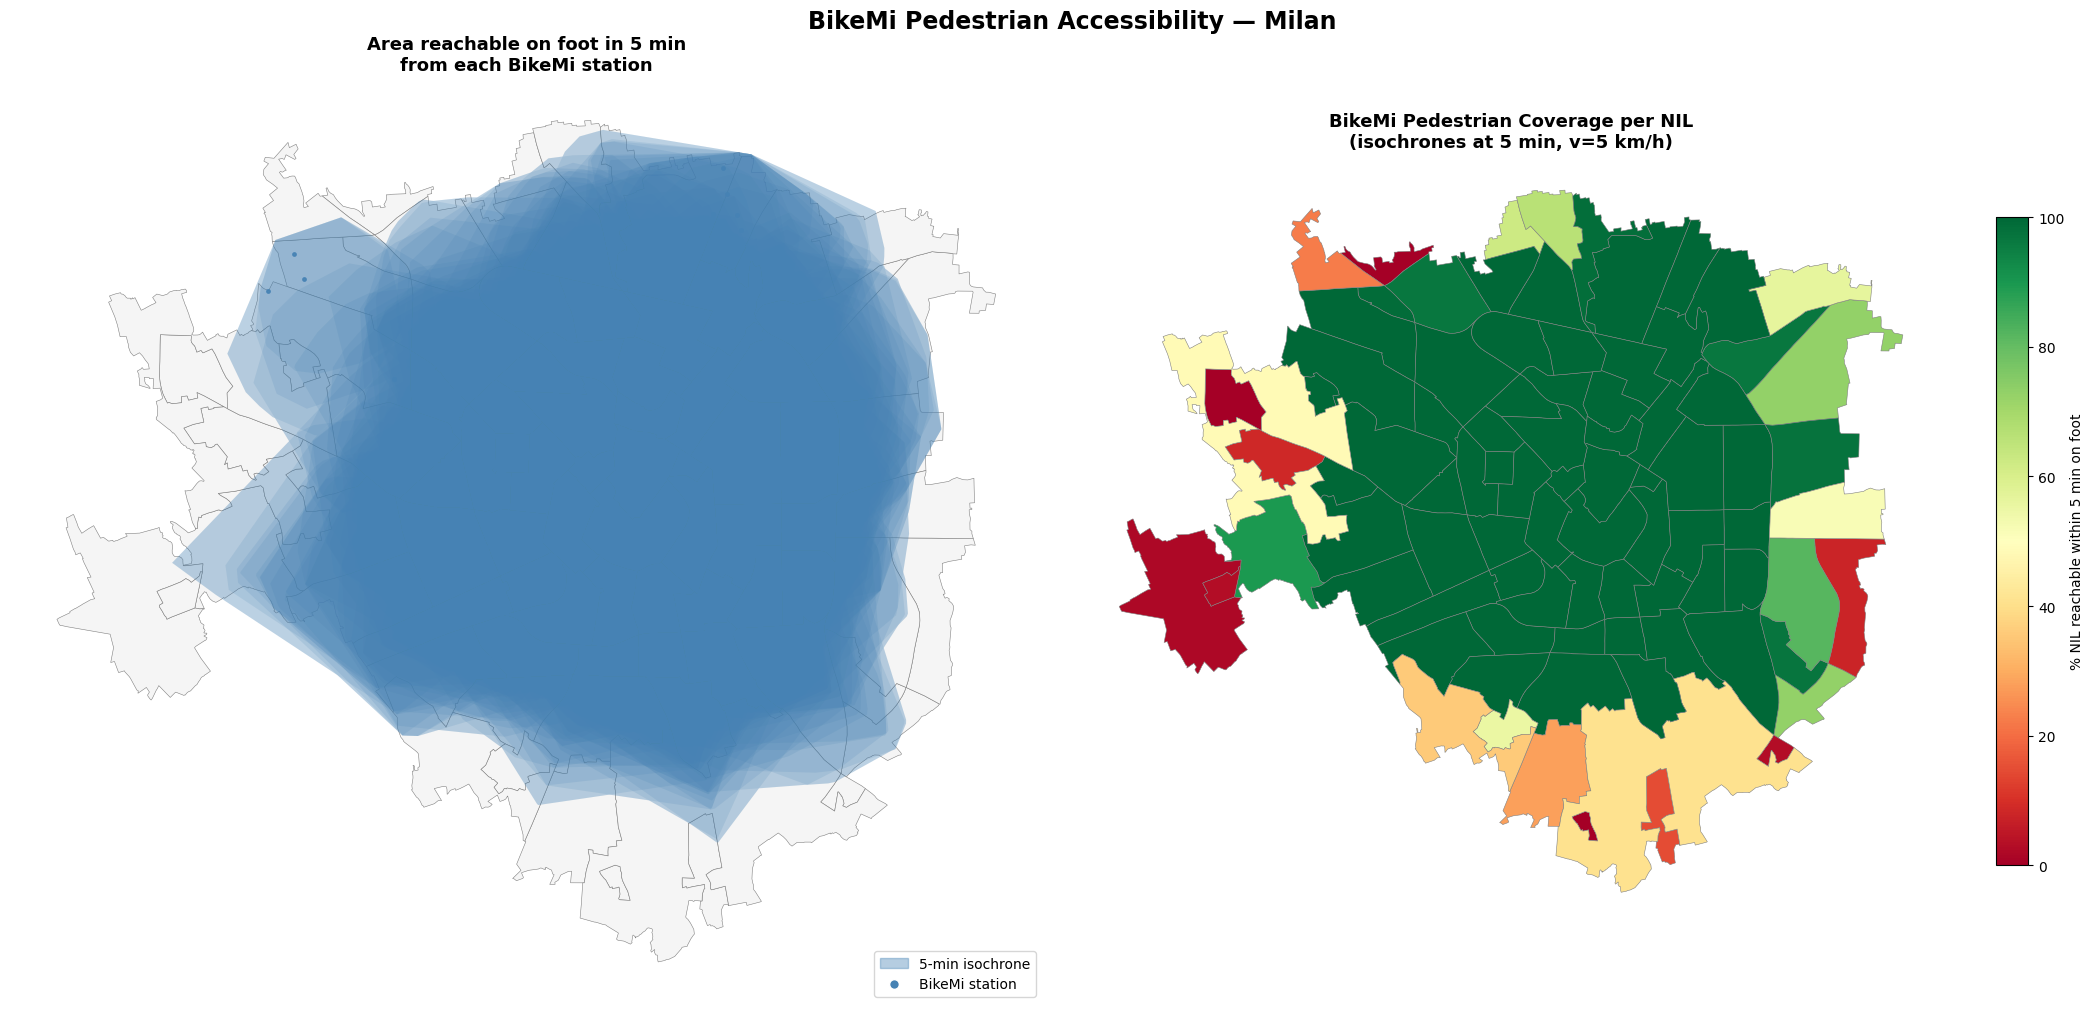

  Saved: 04_isochrones_coverage.png


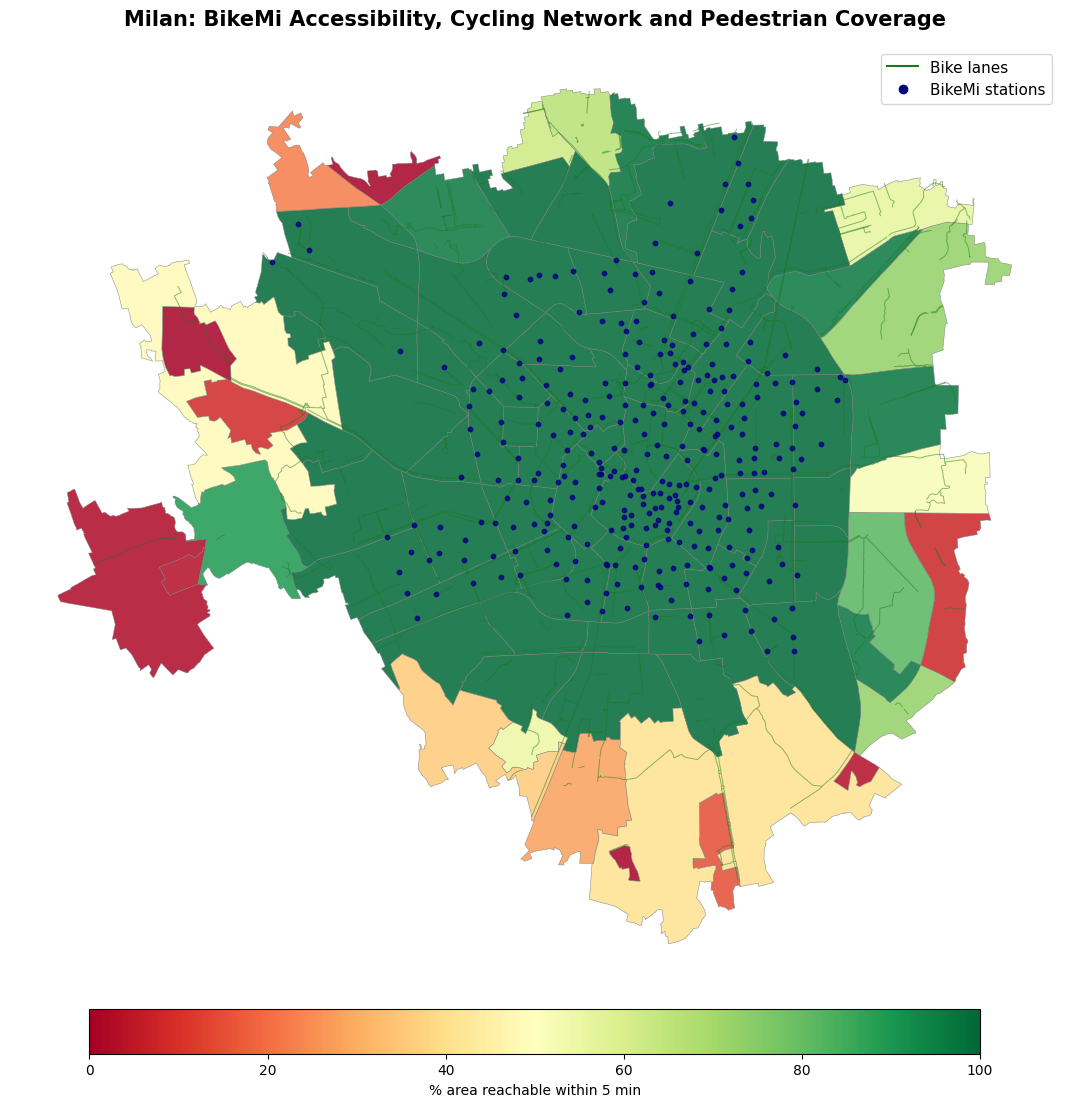

  Saved: 05_combined_final_map.png

  Coverage data saved to: nil_pedestrian_coverage.csv

SUMMARY CELL 2
  Average coverage per NIL: 83.0%
  NIL with coverage < 10%:    8
  NIL with coverage >= 75%:   67

Outputs generated:
  04_isochrones_coverage.png
  05_combined_final_map.png
  nil_pedestrian_coverage.csv


In [ ]:
############################################################
# 5-minute pedestrian isochrones from each BikeMi station
############################################################

import networkx as nx
import osmnx as ox
from shapely.ops import unary_union
import warnings
warnings.filterwarnings("ignore")

WALKING_SPEED_KMH = 5
ISOCHRONE_MINUTES = 5
GRAPH_CACHE = "milan_walk_graph.graphml"

radius_m = (WALKING_SPEED_KMH * 1000 / 60) * ISOCHRONE_MINUTES
print(f"Walking radius at {ISOCHRONE_MINUTES} min: {radius_m:.0f} m")

# DOWNLOAD
print("\n" + "=" * 55)
print("PEDESTRIAN STREET NETWORK (OSMnx)")
print("=" * 55)

import os
if os.path.exists(GRAPH_CACHE):
    print(f"Loading graph from cache: {GRAPH_CACHE}")
    G = ox.load_graphml(GRAPH_CACHE)
else:
    print("  Downloading Milan pedestrian network from OpenStreetMap...")
    G = ox.graph_from_place("Milan, Italy", network_type="walk")
    ox.save_graphml(G, GRAPH_CACHE)
    print(f"  Graph saved to cache: {GRAPH_CACHE}")

print(f"  Nodes: {len(G.nodes):,} | Edges: {len(G.edges):,}")

G = ox.add_edge_speeds(G, fallback=WALKING_SPEED_KMH * 1000 / 3600)
G = ox.add_edge_travel_times(G)

# ISOCHRONE COMPUTATION
print("\n" + "=" * 55)
print("PEDESTRIAN ISOCHRONE COMPUTATION")
print("=" * 55)

time_seconds = ISOCHRONE_MINUTES * 60
isochrone_polygons = []
valid_stations = []

print(f"  Computing isochrone for {len(bikemi_gdf)} stations...")

for idx, station in bikemi_gdf.iterrows():
    try:
        center_node = ox.nearest_nodes(
            G, station.geometry.x, station.geometry.y
        )
        subgraph = nx.ego_graph(
            G, center_node, radius=time_seconds, distance="travel_time"
        )
        reachable_nodes = ox.graph_to_gdfs(subgraph, edges=False)

        if len(reachable_nodes) >= 3:
            polygon = reachable_nodes.geometry.unary_union.convex_hull
        else:
            point_utm = gpd.GeoSeries(
                [station.geometry], crs="EPSG:4326"
            ).to_crs("EPSG:32632").iloc[0]
            polygon = gpd.GeoSeries(
                [point_utm.buffer(radius_m)], crs="EPSG:32632"
            ).to_crs("EPSG:4326").iloc[0]

        isochrone_polygons.append(polygon)
        valid_stations.append(idx)

    except Exception:
        point_utm = gpd.GeoSeries(
            [station.geometry], crs="EPSG:4326"
        ).to_crs("EPSG:32632").iloc[0]
        polygon = gpd.GeoSeries(
            [point_utm.buffer(radius_m)], crs="EPSG:32632"
        ).to_crs("EPSG:4326").iloc[0]
        isochrone_polygons.append(polygon)
        valid_stations.append(idx)

print(f"Isochrones computed: {len(isochrone_polygons)}")

isochrones_gdf = gpd.GeoDataFrame(
    bikemi_gdf.loc[valid_stations].reset_index(drop=True),
    geometry=isochrone_polygons,
    crs="EPSG:4326"
)
coverage_union = unary_union(isochrone_polygons)
isochrones_union_gdf = gpd.GeoDataFrame(
    geometry=[coverage_union], crs="EPSG:4326"
)

# COVERAGE PER NIL
print("\n" + "=" * 55)
print("PEDESTRIAN COVERAGE PER NIL")
print("=" * 55)

nil_utm2 = nil_gdf.to_crs("EPSG:32632").copy()
iso_utm  = isochrones_union_gdf.to_crs("EPSG:32632")

nil_utm2["total_area_m2"] = nil_utm2.geometry.area

intersect = gpd.overlay(nil_utm2, iso_utm, how="intersection")
intersect["covered_area_m2"] = intersect.geometry.area

coverage_nil = (
    intersect.groupby("NIL")["covered_area_m2"].sum().reset_index()
)
nil_utm2 = nil_utm2.merge(coverage_nil, on="NIL", how="left")
nil_utm2["covered_area_m2"] = nil_utm2["covered_area_m2"].fillna(0)
nil_utm2["pct_covered"] = (
    nil_utm2["covered_area_m2"] / nil_utm2["total_area_m2"] * 100
).round(1)

nil_coverage = nil_gdf.merge(
    nil_utm2[["NIL", "pct_covered"]], on="NIL", how="left"
)

print(f"\n  Average % of NIL reached within 5 min: "
      f"{nil_coverage['pct_covered'].mean():.1f}%")
print(f"\n  Top 10 NIL by pedestrian coverage:")
print(
    nil_coverage[["NIL", "pct_covered"]]
    .sort_values("pct_covered", ascending=False)
    .head(10).to_string(index=False)
)
print(f"\n  NIL with coverage < 10%:")
print(
    nil_coverage[nil_coverage["pct_covered"] < 10][["NIL", "pct_covered"]]
    .sort_values("pct_covered")
    .to_string(index=False)
)

# VISUALISATIONS
print("\n" + "=" * 55)
print("VISUALISATIONS")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

nil_gdf.plot(ax=axes[0], color="whitesmoke", edgecolor="gray", linewidth=0.4)
isochrones_gdf.plot(ax=axes[0], color="steelblue", alpha=0.15, zorder=2)
isochrones_union_gdf.plot(ax=axes[0], color="steelblue", alpha=0.25, zorder=3)
bikemi_gdf.plot(ax=axes[0], color="steelblue", markersize=6,
                alpha=0.9, zorder=5)
axes[0].set_title(
    f"Area reachable on foot in {ISOCHRONE_MINUTES} min\n"
    "from each BikeMi station",
    fontsize=13, fontweight="bold"
)
axes[0].set_facecolor("#eaf2fb")
axes[0].axis("off")
patch_iso = mpatches.Patch(color="steelblue", alpha=0.4,
                           label="5-min isochrone")
dot_st = plt.Line2D([0], [0], marker="o", color="w",
                       markerfacecolor="steelblue", markersize=7,
                       label="BikeMi station")
axes[0].legend(handles=[patch_iso, dot_st], fontsize=10, loc="lower right")

nil_coverage.plot(
    ax=axes[1], column="pct_covered", cmap="RdYlGn", legend=True,
    legend_kwds={"label": "% NIL reachable within 5 min on foot",
                 "shrink": 0.7},
    edgecolor="gray", linewidth=0.4, vmin=0, vmax=100,
)
axes[1].set_title(
    "BikeMi Pedestrian Coverage per NIL\n"
    f"(isochrones at {ISOCHRONE_MINUTES} min, v={WALKING_SPEED_KMH} km/h)",
    fontsize=13, fontweight="bold"
)
axes[1].set_facecolor("#eaf2fb")
axes[1].axis("off")

plt.suptitle("BikeMi Pedestrian Accessibility — Milan",
             fontsize=17, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("04_isochrones_coverage.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 04_isochrones_coverage.png")

# final combined map
fig, ax = plt.subplots(figsize=(14, 12))
nil_coverage.plot(
    ax=ax, column="pct_covered", cmap="RdYlGn", legend=True,
    legend_kwds={"label": "% area reachable within 5 min",
                 "shrink": 0.65, "orientation": "horizontal", "pad": 0.02},
    edgecolor="gray", linewidth=0.4, vmin=0, vmax=100, alpha=0.85
)
bike_lanes_gdf.plot(ax=ax, color="#1a7a1a", linewidth=0.7, alpha=0.5, zorder=3)
bikemi_gdf.plot(ax=ax, color="navy", markersize=10, alpha=0.8,
                zorder=5, marker="o")
ax.set_title(
    "Milan: BikeMi Accessibility, Cycling Network and Pedestrian Coverage",
    fontsize=15, fontweight="bold", pad=15
)
ax.set_facecolor("#eaf2fb")
ax.axis("off")
legend_elements = [
    plt.Line2D([0], [0], color="#1a7a1a", lw=1.5, label="Bike lanes"),
    plt.Line2D([0], [0], marker="o", color="w",
               markerfacecolor="navy", markersize=8, label="BikeMi stations"),
]
ax.legend(handles=legend_elements, loc="upper right", fontsize=11)
plt.tight_layout()
plt.savefig("05_combined_final_map.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 05_combined_final_map.png")

# EXPORT
nil_coverage.drop(columns=["geometry"]).to_csv(
    "nil_pedestrian_coverage.csv", index=False
)
print("\n  Coverage data saved to: nil_pedestrian_coverage.csv")

print("\n" + "=" * 55)
print("SUMMARY CELL 2")
print("=" * 55)
print(f"  Average coverage per NIL: {nil_coverage['pct_covered'].mean():.1f}%")
print(f"  NIL with coverage < 10%:    "
      f"{len(nil_coverage[nil_coverage['pct_covered'] < 10])}")
print(f"  NIL with coverage >= 75%:   "
      f"{len(nil_coverage[nil_coverage['pct_covered'] >= 75])}")
print("\nOutputs generated:")
for f in ["04_isochrones_coverage.png", "05_combined_final_map.png",
          "nil_pedestrian_coverage.csv"]:
    print(f"  {f}")


BIKE LANE QUALITY ANALYSIS PER NIL

  Type distribution:
tipologia
ciclabile segnaletica     1977
ciclabile sede propria    1487
promiscuo pedoni           416
promiscuo veicoli          274

LANE QUALITY MAP


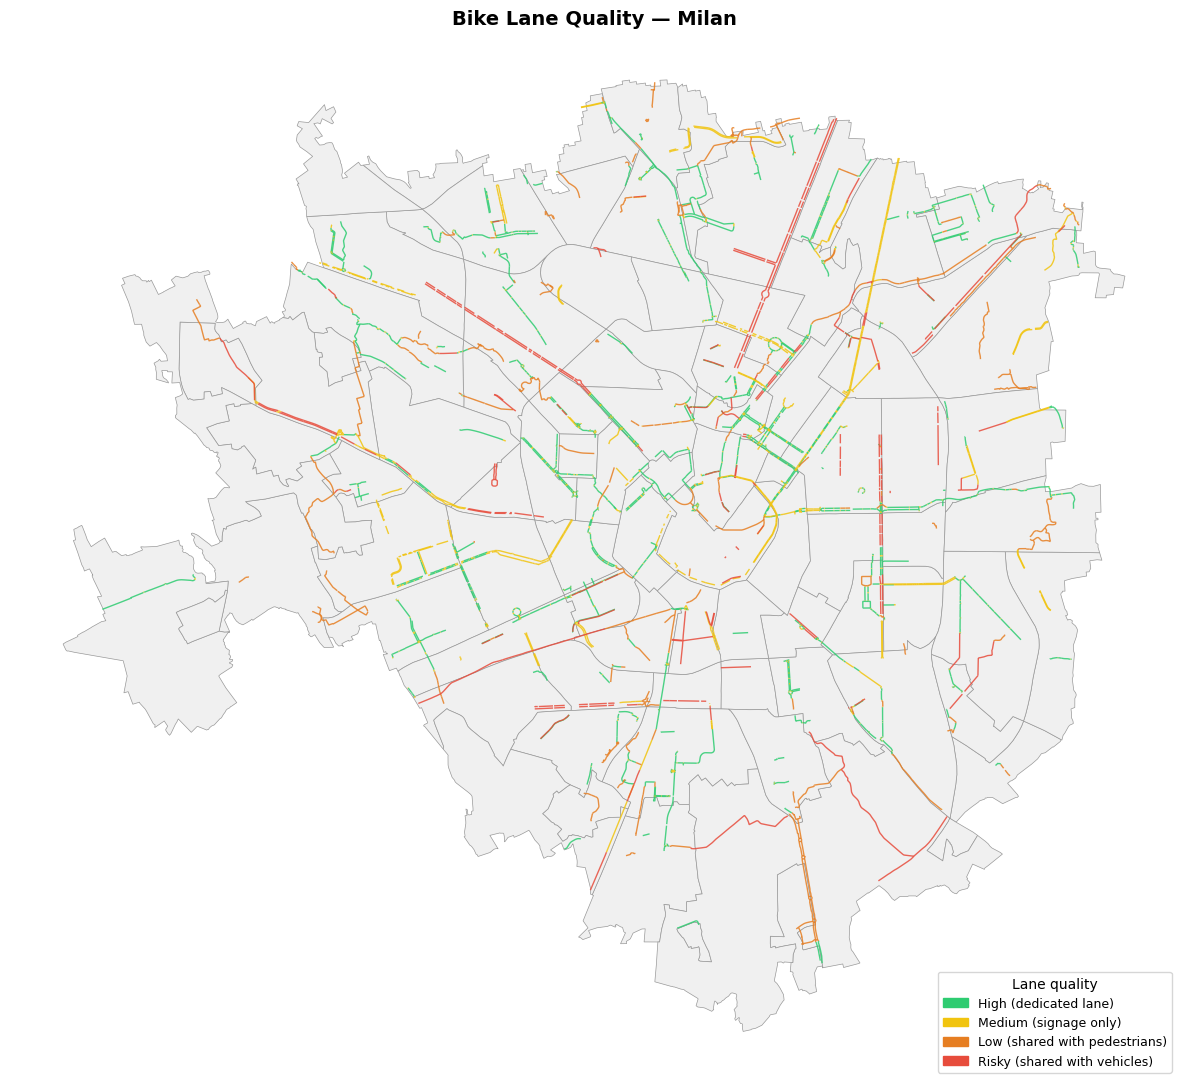

  Saved: 06_lane_quality.png

QUALITY PER NIL

  NIL with >50% high-quality lanes: 26
  NIL with 0 km high-quality lanes: 6

  Top 10 NIL by % high quality:
                   NIL  pct_high  total_km
  RONCHETTO DELLE RANE     100.0  0.446091
                FARINI     100.0  0.267731
    PARCO AGRICOLO SUD      97.2  1.858682
        PARCO SEMPIONE      97.1  1.987575
               DERGANO      81.3  1.727127
DE ANGELI - MONTE ROSA      81.2  4.163338
               CORSICA      79.8  0.711689
GIARDINI PORTA VENEZIA      74.8  1.654665
              CENTRALE      71.4  5.070879
  MAGENTA - S. VITTORE      68.3  2.825339

QUALITY CHOROPLETH


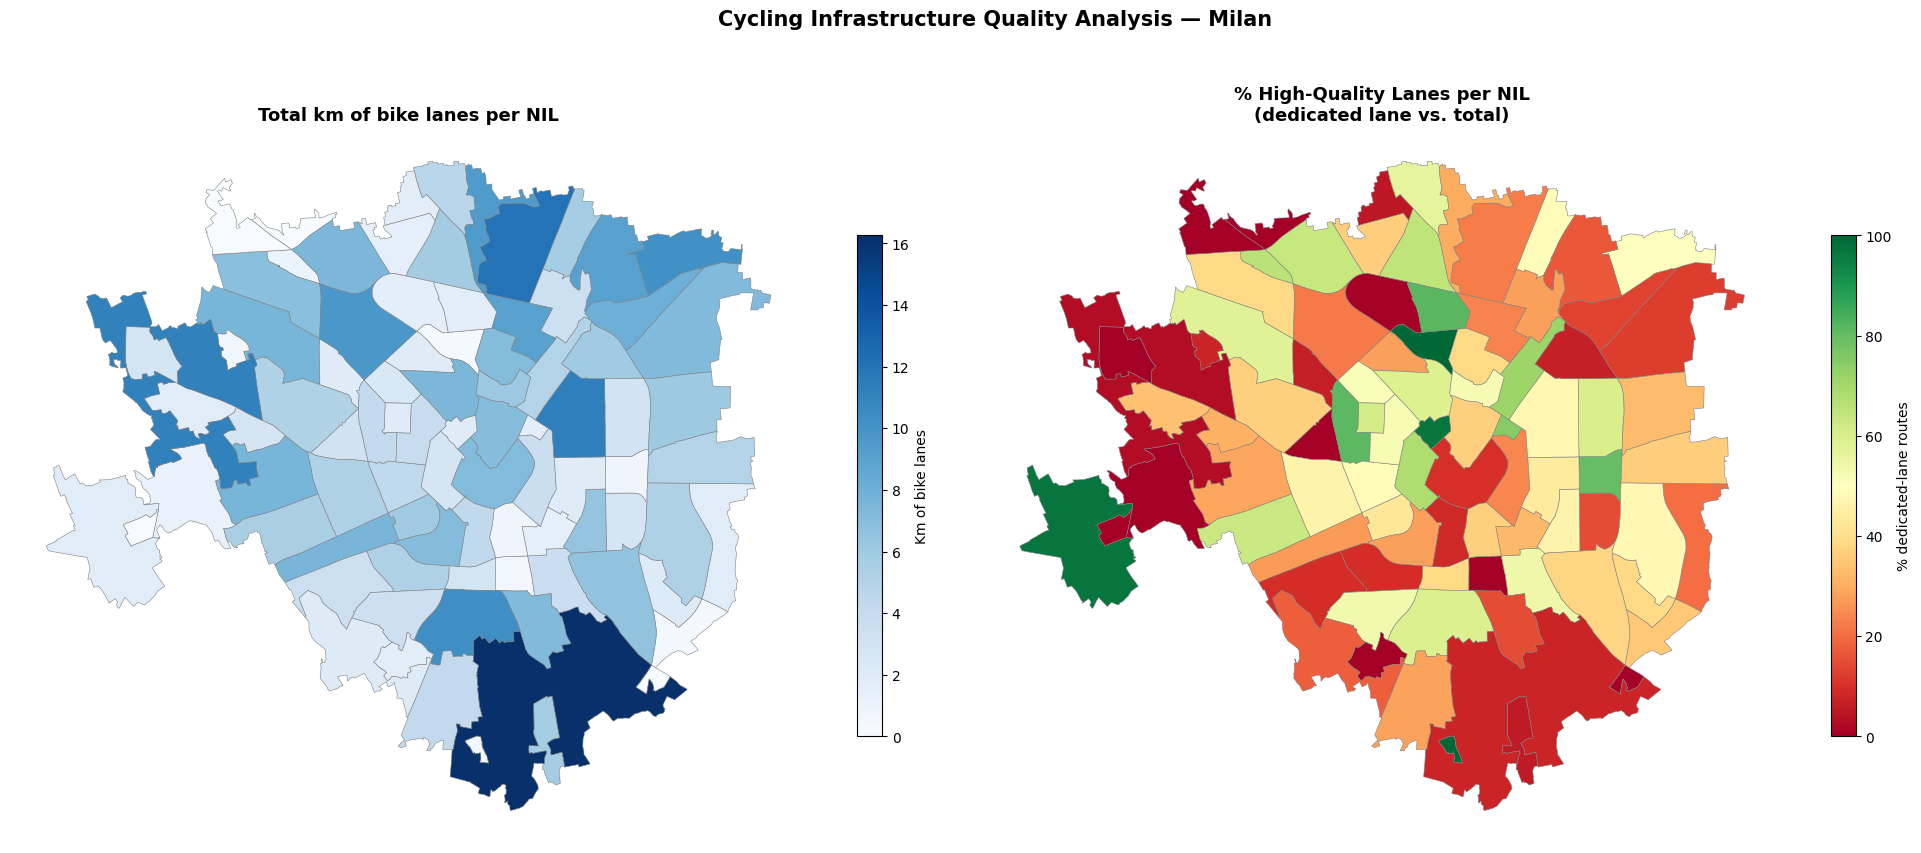

  Saved: 07_quality_choropleth.png

QUALITY STACKED BAR


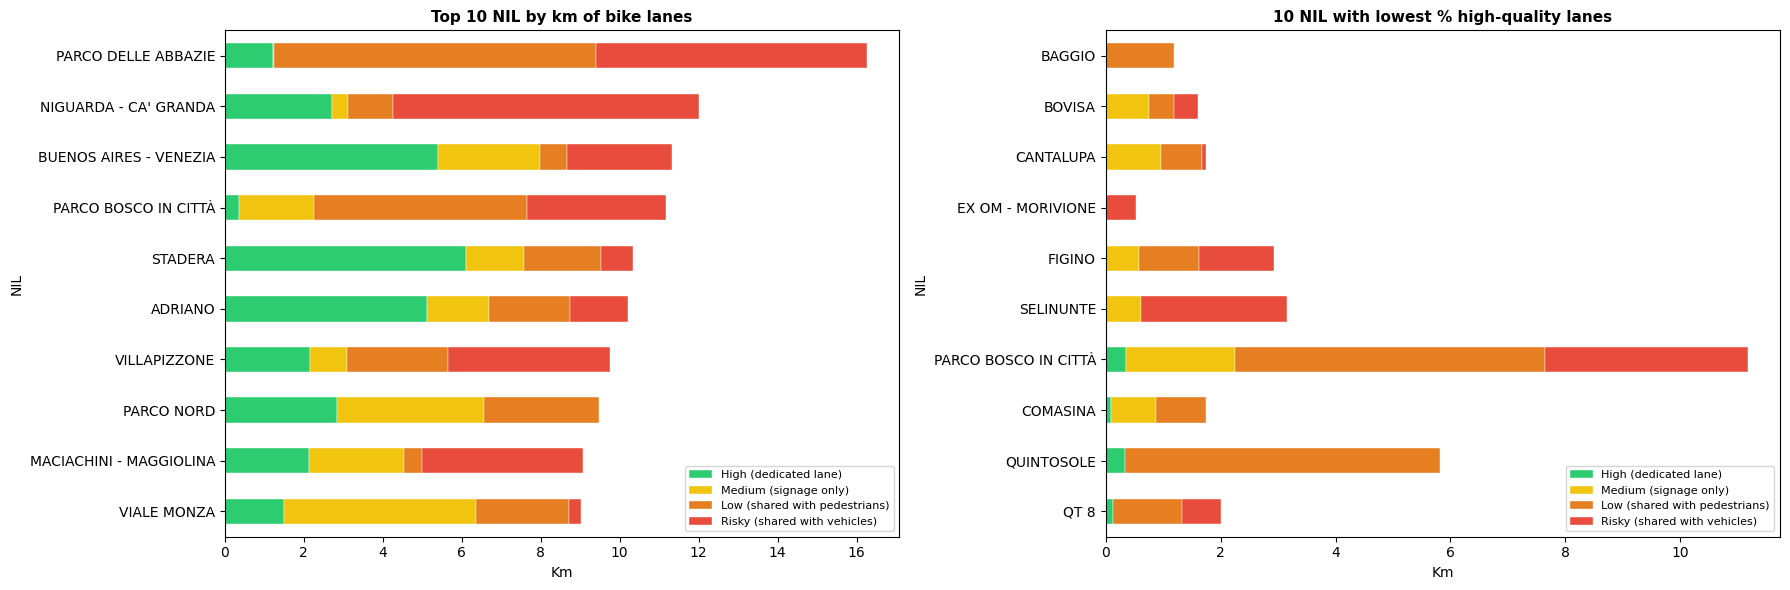

  Saved: 08_quality_bar.png

  Quality data saved to: nil_bike_lane_quality.csv

SUMMARY:
  Total km analysed:  336.0 km
  High quality (dedicated lane): 123.0 km (36.6%)
  Medium (signage only): 79.8 km (23.8%)
  Low (shared with pedestrians): 62.4 km (18.6%)
  Risky (shared with vehicles): 70.8 km (21.1%)

Outputs generated:
  06_lane_quality.png
  07_quality_choropleth.png
  08_quality_bar.png
  nil_bike_lane_quality.csv


In [ ]:
###############################################
# bike lane quality analysis per NIL
##############################################

print("=" * 55)
print("BIKE LANE QUALITY ANALYSIS PER NIL")
print("=" * 55)

# quality map
QUALITY_MAP = {
    'ciclabile sede propria': 'High (dedicated lane)',
    'ciclabile segnaletica': 'Medium (signage only)',
    'promiscuo pedoni': 'Low (shared with pedestrians)',
    'promiscuo veicoli':'Risky (shared with vehicles)',
}
QUALITY_COLORS = {
    'High (dedicated lane)': '#2ecc71',
    'Medium (signage only)': '#f1c40f',
    'Low (shared with pedestrians)': '#e67e22',
    'Risky (shared with vehicles)':'#e74c3c',
}

bike_lanes_gdf['quality'] = bike_lanes_gdf['tipologia'].map(QUALITY_MAP)

print("\n  Type distribution:")
print(bike_lanes_gdf['tipologia'].value_counts().to_string())

# MAP LANES COLOURED BY QUALITY
print("\n" + "=" * 55)
print("LANE QUALITY MAP")
print("=" * 55)

fig, ax = plt.subplots(figsize=(13, 11))
nil_gdf.plot(ax=ax, color='#f0f0f0', edgecolor='#999',
             linewidth=0.5, zorder=1)

for quality, color in QUALITY_COLORS.items():
    subset = bike_lanes_gdf[bike_lanes_gdf['quality'] == quality]
    subset.plot(ax=ax, color=color, linewidth=1,
                alpha=0.85, zorder=2, label=quality)

patches = [mpatches.Patch(color=c, label=l)
           for l, c in QUALITY_COLORS.items()]
ax.legend(handles=patches, loc='lower right',
          fontsize=9, title='Lane quality')
ax.set_title('Bike Lane Quality — Milan',
             fontsize=14, fontweight='bold')
ax.set_facecolor('#eaf2fb')
ax.axis('off')
plt.tight_layout()
plt.savefig('06_lane_quality.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: 06_lane_quality.png")

# QUALITY AGGREGATION PER NIL
print("\n" + "=" * 55)
print("QUALITY PER NIL")
print("=" * 55)

lanes_utm2 = bike_lanes_gdf.to_crs('EPSG:32632').copy()
nil_utm2   = nil_gdf.to_crs('EPSG:32632').copy()

lanes_utm2['quality'] = bike_lanes_gdf['quality'].values
lanes_utm2['len_m']   = lanes_utm2.geometry.length

joined_q = gpd.sjoin(
    lanes_utm2[['quality', 'len_m', 'geometry']],
    nil_utm2[['NIL', 'geometry']],
    how='left', predicate='intersects'
)

quality_nil = (
    joined_q.groupby(['NIL', 'quality'])['len_m']
    .sum()
    .reset_index()
)
quality_nil['len_km'] = quality_nil['len_m'] / 1000

quality_pivot = quality_nil.pivot_table(
    index='NIL', columns='quality',
    values='len_km', aggfunc='sum', fill_value=0
).reset_index()

# ensure all columns exist
for col in QUALITY_COLORS.keys():
    if col not in quality_pivot.columns:
        quality_pivot[col] = 0.0

quality_pivot['total_km'] = (
    quality_pivot[list(QUALITY_COLORS.keys())].sum(axis=1)
)
quality_pivot['pct_high'] = (
    quality_pivot['High (dedicated lane)']
    / quality_pivot['total_km'].replace(0, np.nan) * 100
).fillna(0).round(1)

print(f"\n  NIL with >50% high-quality lanes: "
      f"{(quality_pivot['pct_high'] > 50).sum()}")
print(f"  NIL with 0 km high-quality lanes: "
      f"{(quality_pivot['High (dedicated lane)'] == 0).sum()}")

print(f"\n  Top 10 NIL by % high quality:")
print(
    quality_pivot[['NIL', 'pct_high', 'total_km']]
    .sort_values('pct_high', ascending=False)
    .head(10).to_string(index=False)
)

# CHOROPLETH total km + % high quality
print("\n" + "=" * 55)
print("QUALITY CHOROPLETH")
print("=" * 55)

nil_q = nil_gdf.merge(quality_pivot, on='NIL', how='left').fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

nil_q.plot(
    column='total_km', ax=axes[0], cmap='Blues', legend=True,
    legend_kwds={'label': 'Km of bike lanes', 'shrink': 0.6},
    edgecolor='gray', linewidth=0.4,
    missing_kwds={'color': 'lightgrey'}
)
axes[0].set_title('Total km of bike lanes per NIL',
                  fontweight='bold', fontsize=13)
axes[0].set_facecolor('#eaf2fb')
axes[0].axis('off')

nil_q.plot(
    column='pct_high', ax=axes[1], cmap='RdYlGn',
    vmin=0, vmax=100, legend=True,
    legend_kwds={'label': '% dedicated-lane routes', 'shrink': 0.6},
    edgecolor='gray', linewidth=0.4,
)
axes[1].set_title(
    '% High-Quality Lanes per NIL\n(dedicated lane vs. total)',
    fontweight='bold', fontsize=13
)
axes[1].set_facecolor('#eaf2fb')
axes[1].axis('off')

plt.suptitle('Cycling Infrastructure Quality Analysis — Milan',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('07_quality_choropleth.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: 07_quality_choropleth.png")

# STACKED BAR — top 10 NIL by km and bottom 10 by quality
print("\n" + "=" * 55)
print("QUALITY STACKED BAR")
print("=" * 55)

top10_km  = quality_pivot.nlargest(10, 'total_km').copy()
bot10_q = (quality_pivot[quality_pivot['total_km'] > 0]
               .nsmallest(10, 'pct_high').copy())

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, df, title in zip(
    axes,
    [top10_km, bot10_q],
    ['Top 10 NIL by km of bike lanes',
     '10 NIL with lowest % high-quality lanes']
):
    df_plot = df.set_index('NIL')[list(QUALITY_COLORS.keys())]
    df_plot.plot(
        kind='barh', stacked=True, ax=ax,
        color=list(QUALITY_COLORS.values()),
        edgecolor='white', linewidth=0.3
    )
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xlabel('Km')
    ax.legend(fontsize=8, loc='lower right')
    ax.invert_yaxis()

plt.tight_layout()
plt.savefig('08_quality_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: 08_quality_bar.png")

# EXPORT + SUMMARY
quality_pivot.to_csv('nil_bike_lane_quality.csv', index=False)
print("\n  Quality data saved to: nil_bike_lane_quality.csv")

tot_km = lanes_utm2['len_m'].sum() / 1000
high_km = lanes_utm2[lanes_utm2['quality'] == 'High (dedicated lane)']['len_m'].sum() / 1000

print("\n" + "=" * 55)
print("SUMMARY:")
print("=" * 55)
print(f"  Total km analysed:  {tot_km:.1f} km")
print(f"  High quality (dedicated lane): {high_km:.1f} km "
      f"({high_km/tot_km*100:.1f}%)")
for q, label in [
    ('Medium (signage only)', 'Medium (signage only):'),
    ('Low (shared with pedestrians)', 'Low (shared with pedestrians):'),
    ('Risky (shared with vehicles)','Risky (shared with vehicles):'),
]:
    km = lanes_utm2[lanes_utm2['quality'] == q]['len_m'].sum() / 1000
    print(f"  {label} {km:.1f} km ({km/tot_km*100:.1f}%)")

print("\nOutputs generated:")
for f in ['06_lane_quality.png', '07_quality_choropleth.png',
          '08_quality_bar.png', 'nil_bike_lane_quality.csv']:
    print(f"  {f}")



LOADING IRPEF INCOME DATA 2022
  ZIP codes analysed: 38
  Min avg income: €18,509 (ZIP 20157)
  Max avg income: €94,369 (ZIP 20121)

ZIP CODE MAPPING
  ZIP centroids created: 38
  ZIPs mapped to a NIL: 35
  ZIPs without NIL: 3

  NIL with income data: 32

  Top 5 NIL by income:
                   NIL  weighted_avg_income
                 BRERA              94369.0
DE ANGELI - MONTE ROSA              83768.0
  MAGENTA - S. VITTORE              74232.0
                 DUOMO              59924.0
BUENOS AIRES - VENEZIA              56142.0

  Bottom 5 NIL by income:
           NIL  weighted_avg_income
 QUINTO ROMANO              18509.0
QUARTO OGGIARO              23602.0
   VIALE MONZA              23820.0
       STADERA              24122.0
        AFFORI              24578.0

FULL NIL DATASET
  NIL with complete data: 32

CORRELATIONS WITH INCOME

  Variable                                         r    p-value  Signif.
  ----------------------------------------------------------------

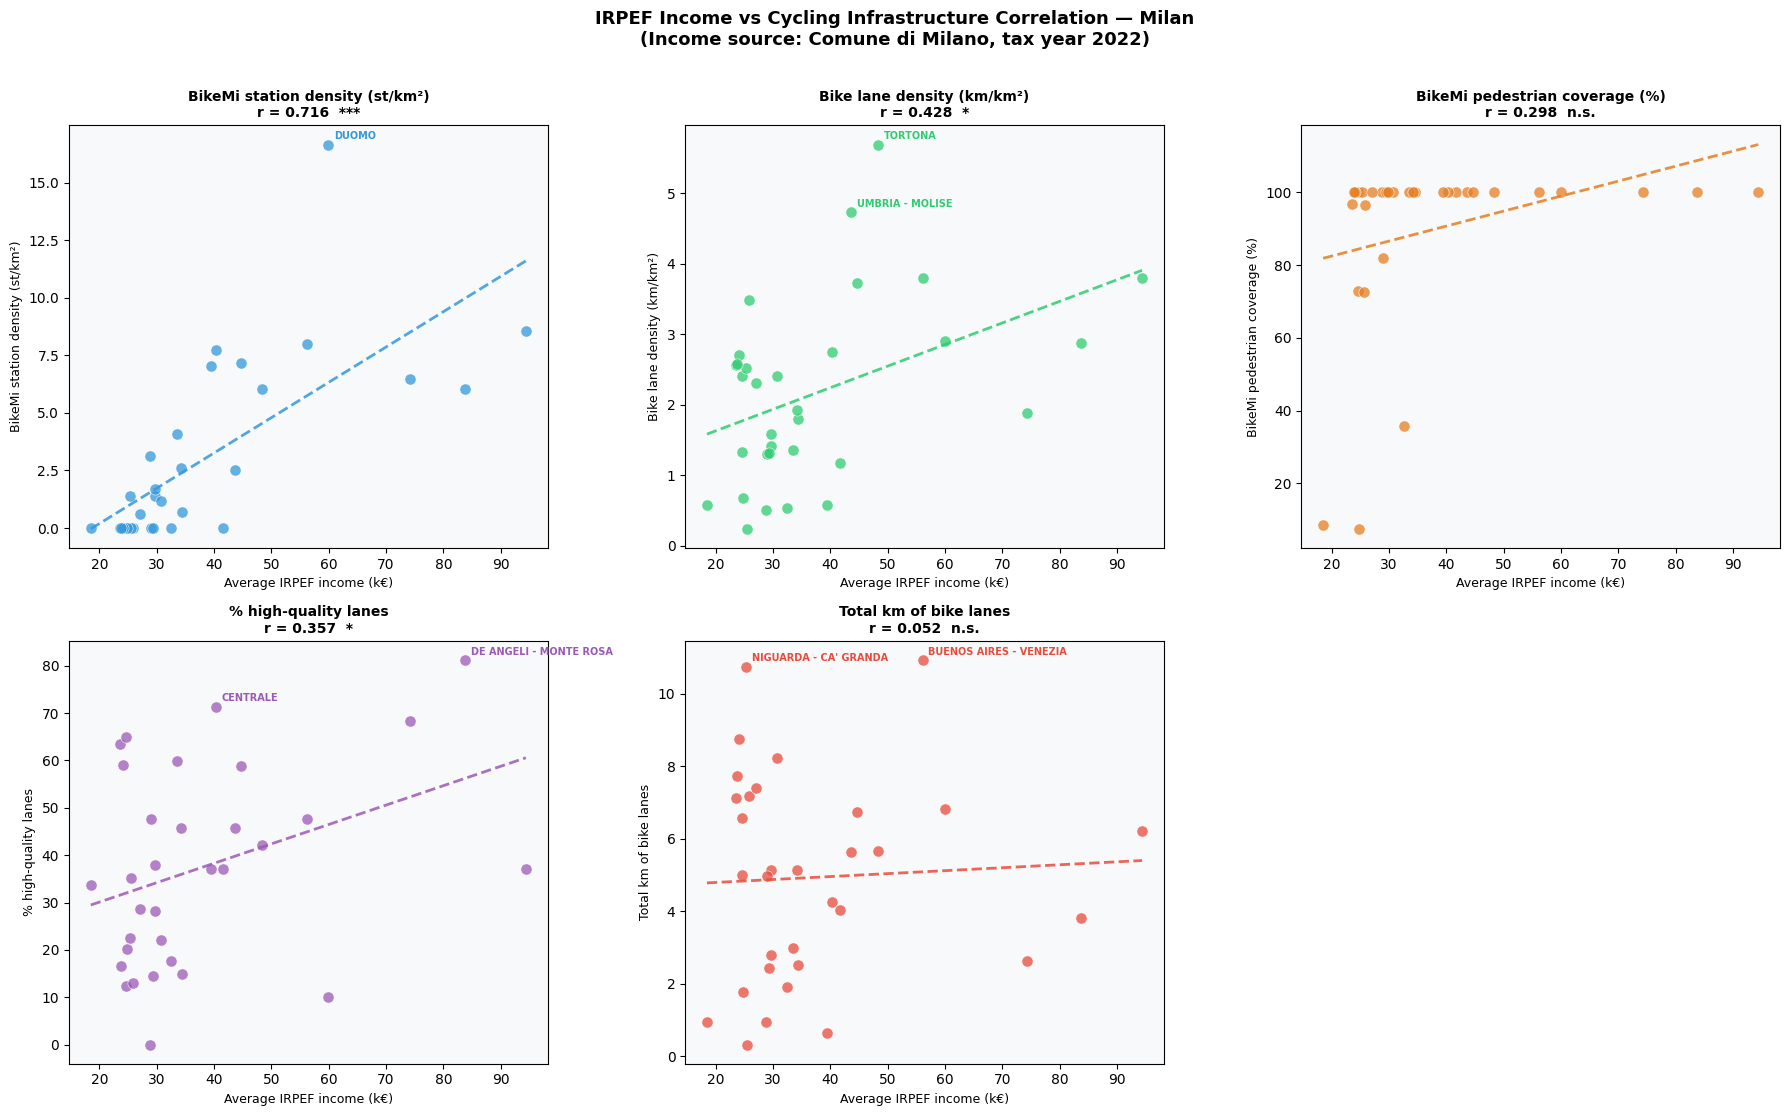

  Saved: 09_income_correlations.png

CORRELATION HEATMAP


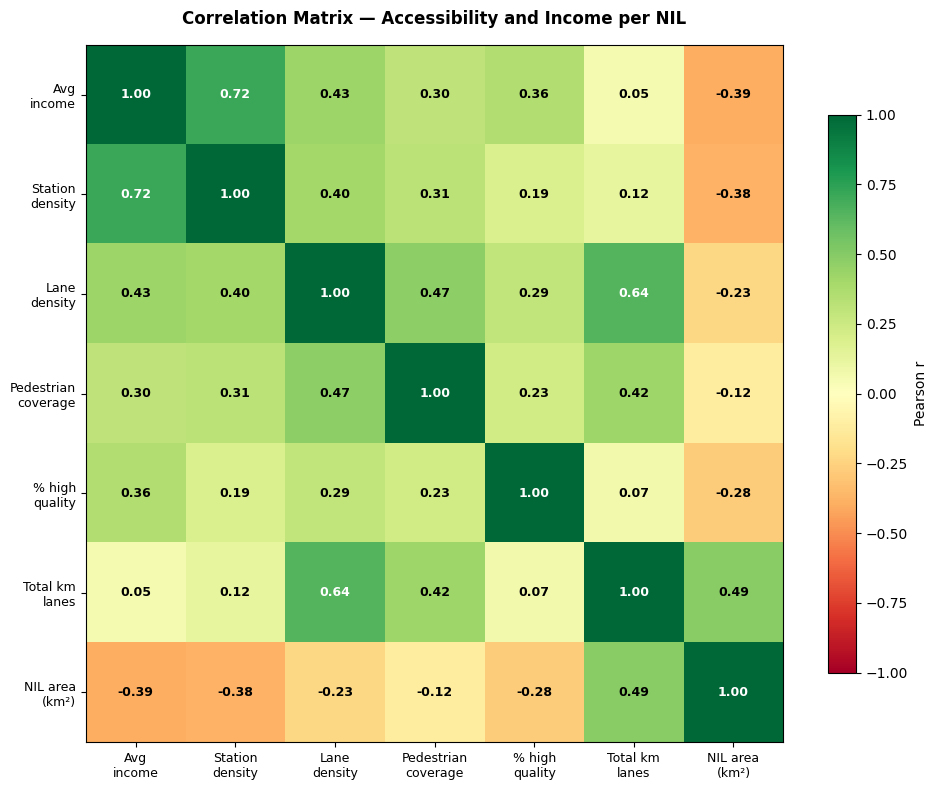

  Saved: 10_correlation_heatmap.png

INCOME MAP PER NIL


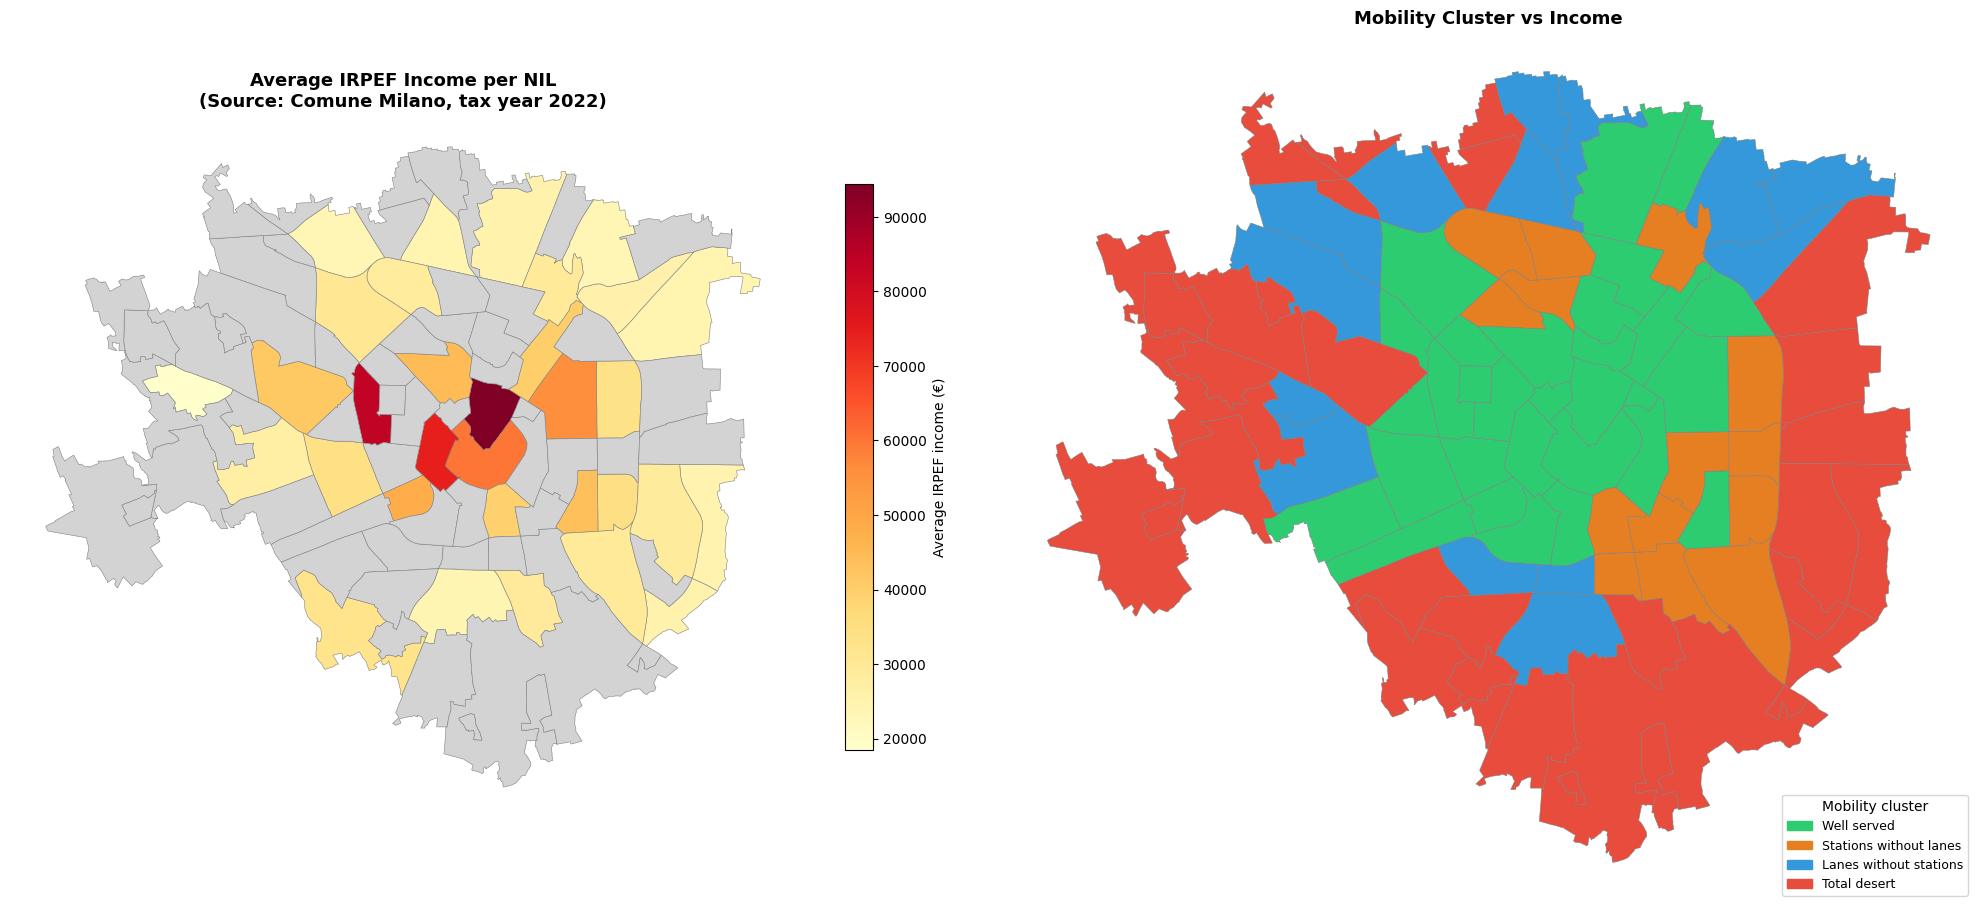

  Saved: 12_income_nil_map.png


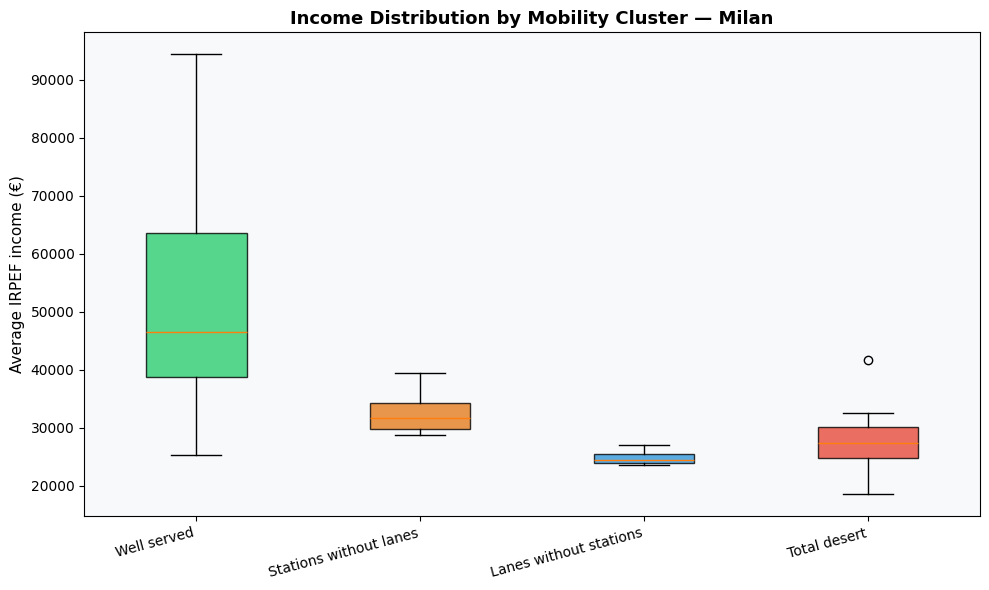

  Saved: 11_income_boxplot_cluster.png

  Complete dataset saved: nil_socioeconomic_complete.csv

SUMMARY:
  NIL with complete data: 32
  ZIP codes analysed:     38

  Main correlations with IRPEF income:
    BikeMi station density (st/km²)          r=+0.716  ***
    Bike lane density (km/km²)               r=+0.428  *
    BikeMi pedestrian coverage (%)           r=+0.298  n.s.
    % high-quality lanes                     r=+0.357  *
    Total km of bike lanes                   r=+0.052  n.s.

Outputs generated:
  09_income_correlations.png
  10_correlation_heatmap.png
  11_income_boxplot_cluster.png
  12_income_nil_map.png
  nil_socioeconomic_complete.csv


In [ ]:
########################################################
# Socioeconomic data (IRPEF income tax) and correlations
#######################################################
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
import numpy as np
from scipy import stats
import os
import warnings
warnings.filterwarnings("ignore")

# LOAD IRPEF INCOME DATA
print("\n" + "=" * 55)
print("LOADING IRPEF INCOME DATA 2022")
print("=" * 55)

INCOME_CSV = os.path.join(FOLDER, "redditi_irpef_2022.csv")
df_irpef = pd.read_csv(INCOME_CSV, sep=";", encoding="utf-8")

income_total = (
    df_irpef[df_irpef["Redditi e variabili Irpef"]
             == "Reddito imponibile - Ammontare in euro"]
    [["CAP", "Importi"]].rename(columns={"Importi": "total_income"})
)
taxpayers = (
    df_irpef[df_irpef["Redditi e variabili Irpef"]
             == "Numero contribuenti"]
    [["CAP", "Importi"]].rename(columns={"Importi": "n_taxpayers"})
)
income_cap = income_total.merge(taxpayers, on="CAP")
income_cap["avg_income"] = (
    income_cap["total_income"] / income_cap["n_taxpayers"]
).round(0)

print(f"  ZIP codes analysed: {len(income_cap)}")
print(f"  Min avg income: €{income_cap['avg_income'].min():,.0f} "
      f"(ZIP {income_cap.loc[income_cap['avg_income'].idxmin(),'CAP']})")
print(f"  Max avg income: €{income_cap['avg_income'].max():,.0f} "
      f"(ZIP {income_cap.loc[income_cap['avg_income'].idxmax(),'CAP']})")

# ZIP CODE MAPPING
print("\n" + "=" * 55)
print("ZIP CODE MAPPING")
print("=" * 55)

from shapely.geometry import Point

cap_coords = {
    20121: (9.1860, 45.4745), 20122: (9.1940, 45.4635),
    20123: (9.1740, 45.4640), 20124: (9.2020, 45.4780),
    20125: (9.2050, 45.4880), 20126: (9.2440, 45.4580),
    20127: (9.2580, 45.5020), 20128: (9.2260, 45.5020),
    20129: (9.2160, 45.4700), 20131: (9.2320, 45.4800),
    20132: (9.2680, 45.4780), 20133: (9.2360, 45.4580),
    20134: (9.2540, 45.4420), 20135: (9.2160, 45.4500),
    20136: (9.1960, 45.4480), 20137: (9.2300, 45.4420),
    20138: (9.2600, 45.4420), 20139: (9.2620, 45.4320),
    20141: (9.1940, 45.4320), 20142: (9.1760, 45.4240),
    20143: (9.1520, 45.4240), 20144: (9.1620, 45.4560),
    20145: (9.1520, 45.4700), 20146: (9.1340, 45.4580),
    20147: (9.1060, 45.4580), 20148: (9.1200, 45.4780),
    20149: (9.1360, 45.4740), 20151: (9.1400, 45.4920),
    20152: (9.1120, 45.4380), 20153: (9.0980, 45.4200),
    20154: (9.1760, 45.4860), 20155: (9.1640, 45.5020),
    20156: (9.1360, 45.5080), 20157: (9.0980, 45.4800),
    20158: (9.1800, 45.5100), 20159: (9.2060, 45.5080),
    20161: (9.2260, 45.5200), 20162: (9.2040, 45.5260),
}

cap_gdf = gpd.GeoDataFrame(
    {"CAP": list(cap_coords.keys())},
    geometry=[Point(v) for v in cap_coords.values()],
    crs="EPSG:4326"
)
print(f"  ZIP centroids created: {len(cap_gdf)}")

nil_utm3 = nil_gdf.to_crs("EPSG:32632").copy()
cap_utm  = cap_gdf.to_crs("EPSG:32632").copy()

cap_nil = gpd.sjoin(
    cap_utm, nil_utm3[["NIL", "geometry"]],
    how="left", predicate="within"
)[["CAP", "NIL"]]

print(f"  ZIPs mapped to a NIL: {cap_nil['NIL'].notna().sum()}")
print(f"  ZIPs without NIL: {cap_nil['NIL'].isna().sum()}")

cap_nil = cap_nil.merge(
    income_cap[["CAP", "avg_income", "n_taxpayers"]],
    on="CAP", how="left"
)

def weighted_avg(group):
    mask = group["n_taxpayers"].notna() & group["avg_income"].notna()
    g = group[mask]
    if len(g) == 0:
        return np.nan
    return np.average(g["avg_income"], weights=g["n_taxpayers"])

nil_income = (
    cap_nil.groupby("NIL")
    .apply(weighted_avg)
    .reset_index()
    .rename(columns={0: "weighted_avg_income"})
)

print(f"\n  NIL with income data: {nil_income['weighted_avg_income'].notna().sum()}")
print(f"\n  Top 5 NIL by income:")
print(nil_income.nlargest(5, "weighted_avg_income").to_string(index=False))
print(f"\n  Bottom 5 NIL by income:")
print(nil_income.nsmallest(5, "weighted_avg_income").to_string(index=False))

# FULL DATASET MERGE
print("\n" + "=" * 55)
print("FULL NIL DATASET")
print("=" * 55)

nil_socio = nil_analysis.copy()
nil_socio = nil_socio.merge(nil_income, on="NIL", how="left")
nil_socio = nil_socio.merge(
    quality_pivot[["NIL", "total_km", "pct_high"]], on="NIL", how="left"
)
nil_socio = nil_socio.merge(
    nil_coverage[["NIL", "pct_covered"]], on="NIL", how="left"
)

nil_clean = nil_socio.dropna(
    subset=["weighted_avg_income", "station_density",
            "lane_density", "pct_covered"]
).copy()

print(f"  NIL with complete data: {len(nil_clean)}")

# CORRELATION ANALYSIS
print("\n" + "=" * 55)
print("CORRELATIONS WITH INCOME")
print("=" * 55)

variables = {
    "station_density": "BikeMi station density (st/km²)",
    "lane_density": "Bike lane density (km/km²)",
    "pct_covered": "BikeMi pedestrian coverage (%)",
    "pct_high": "% high-quality lanes",
    "km_bike_lanes": "Total km of bike lanes",
}

print(f"\n  {'Variable':<42} {'r':>7} {'p-value':>10} {'Signif.':>8}")
print("  " + "-" * 72)

correlations = {}
for var, label in variables.items():
    sub = nil_clean.dropna(subset=[var, "weighted_avg_income"])
    if len(sub) < 5:
        continue
    r, p = stats.pearsonr(sub["weighted_avg_income"], sub[var])
    sig = ("***" if p < 0.001 else "**" if p < 0.01
           else "*" if p < 0.05 else "n.s.")
    correlations[var] = {"label": label, "r": r, "p": p,
                         "sig": sig, "n": len(sub)}
    print(f"  {label:<42} {r:>7.3f} {p:>10.4f} {sig:>8}")

# SCATTER PLOTS
print("\n" + "=" * 55)
print("SCATTER PLOTS")
print("=" * 55)

fig_scatter, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()
colors = ["#3498db", "#2ecc71", "#e67e22", "#9b59b6", "#e74c3c"]

for i, (var, color) in enumerate(zip(variables.keys(), colors)):
    ax = axes[i]
    sub = nil_clean.dropna(subset=[var, "weighted_avg_income"])
    if len(sub) < 5:
        ax.axis("off")
        continue

    ax.scatter(sub["weighted_avg_income"] / 1000, sub[var],
               color=color, alpha=0.75, s=65,
               edgecolors="white", linewidths=0.5)

    m, b, r, p, _ = stats.linregress(
        sub["weighted_avg_income"] / 1000, sub[var]
    )
    x_line = np.linspace(sub["weighted_avg_income"].min() / 1000,
                         sub["weighted_avg_income"].max() / 1000, 100)
    ax.plot(x_line, m * x_line + b, color=color,
            linewidth=2, alpha=0.85, linestyle="--")

    d = correlations.get(var, {})
    ax.set_title(f"{variables[var]}\nr = {r:.3f}  {d.get('sig', '')}",
                 fontsize=10, fontweight="bold")
    ax.set_xlabel("Average IRPEF income (k€)", fontsize=9)
    ax.set_ylabel(variables[var], fontsize=9)
    ax.set_facecolor("#f8f9fa")

    threshold = sub[var].mean() + 1.5 * sub[var].std()
    for _, row in sub[sub[var] > threshold].head(3).iterrows():
        ax.annotate(row["NIL"],
                    (row["weighted_avg_income"] / 1000, row[var]),
                    fontsize=7, xytext=(4, 4),
                    textcoords="offset points",
                    color=color, fontweight="bold")

axes[-1].axis("off")
fig_scatter.suptitle(
    "IRPEF Income vs Cycling Infrastructure Correlation — Milan\n"
    "(Income source: Comune di Milano, tax year 2022)",
    fontsize=13, fontweight="bold", y=1.01
)
fig_scatter.tight_layout()
fig_scatter.savefig("09_income_correlations.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 09_income_correlations.png")

# CORRELATION HEATMAP
print("\n" + "=" * 55)
print("CORRELATION HEATMAP")
print("=" * 55)

cols_h = ["weighted_avg_income", "station_density", "lane_density",
          "pct_covered", "pct_high", "km_bike_lanes", "area_km2"]
labels_h = ["Avg\nincome", "Station\ndensity", "Lane\ndensity",
            "Pedestrian\ncoverage", "% high\nquality", "Total km\nlanes",
            "NIL area\n(km²)"]

corr_mat = nil_clean[cols_h].dropna().corr()

fig_heat, ax_heat = plt.subplots(figsize=(10, 8))
im = ax_heat.imshow(corr_mat.values, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax_heat, shrink=0.8, label="Pearson r")
ax_heat.set_xticks(range(len(labels_h)))
ax_heat.set_yticks(range(len(labels_h)))
ax_heat.set_xticklabels(labels_h, fontsize=9)
ax_heat.set_yticklabels(labels_h, fontsize=9)

for i in range(len(labels_h)):
    for j in range(len(labels_h)):
        val = corr_mat.values[i, j]
        col = "white" if abs(val) > 0.6 else "black"
        ax_heat.text(j, i, f"{val:.2f}", ha="center", va="center",
                     fontsize=9, color=col, fontweight="bold")

ax_heat.set_title("Correlation Matrix — Accessibility and Income per NIL",
                  fontsize=12, fontweight="bold", pad=15)
fig_heat.tight_layout()
fig_heat.savefig("10_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 10_correlation_heatmap.png")

# INCOME MAP
print("\n" + "=" * 55)
print("INCOME MAP PER NIL")
print("=" * 55)

nil_geo_r = nil_gdf.merge(
    nil_socio[["NIL", "weighted_avg_income", "cluster"]], on="NIL", how="left"
)

cluster_colors = {
    "Well served": "#2ecc71",
    "Stations without lanes": "#e67e22",
    "Lanes without stations": "#3498db",
    "Total desert": "#e74c3c",
}
nil_geo_r["color"] = nil_geo_r["cluster"].map(cluster_colors)

fig_map, axes_map = plt.subplots(1, 2, figsize=(20, 9))

nil_geo_r.plot(
    column="weighted_avg_income", ax=axes_map[0], cmap="YlOrRd",
    legend=True,
    legend_kwds={"label": "Average IRPEF income (€)", "shrink": 0.65},
    edgecolor="gray", linewidth=0.4,
    missing_kwds={"color": "lightgrey"}
)
axes_map[0].set_title(
    "Average IRPEF Income per NIL\n(Source: Comune Milano, tax year 2022)",
    fontsize=13, fontweight="bold"
)
axes_map[0].set_facecolor("#eaf2fb")
axes_map[0].axis("off")

nil_geo_r.plot(ax=axes_map[1],
               color=nil_geo_r["color"].fillna("lightgrey"),
               edgecolor="gray", linewidth=0.4)
patch_list = [mpatches.Patch(color=v, label=k)
              for k, v in cluster_colors.items()]
axes_map[1].legend(handles=patch_list, loc="lower right",
                   fontsize=9, title="Mobility cluster")
axes_map[1].set_title("Mobility Cluster vs Income",
                      fontsize=13, fontweight="bold")
axes_map[1].set_facecolor("#eaf2fb")
axes_map[1].axis("off")

fig_map.tight_layout()
fig_map.savefig("12_income_nil_map.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 12_income_nil_map.png")

# INCOME BOXPLOT BY CLUSTER
fig_box, ax_box = plt.subplots(figsize=(10, 6))
cluster_order = ["Well served", "Stations without lanes",
                 "Lanes without stations", "Total desert"]
data_box = [nil_socio[nil_socio["cluster"] == c]["weighted_avg_income"]
            .dropna().values for c in cluster_order]
bp = ax_box.boxplot(data_box, patch_artist=True, notch=False)
for patch, cluster in zip(bp["boxes"], cluster_order):
    patch.set_facecolor(cluster_colors[cluster])
    patch.set_alpha(0.8)

ax_box.set_xticks(range(1, 5))
ax_box.set_xticklabels(cluster_order, rotation=15, ha="right", fontsize=10)
ax_box.set_ylabel("Average IRPEF income (€)", fontsize=11)
ax_box.set_title("Income Distribution by Mobility Cluster — Milan",
                 fontsize=13, fontweight="bold")
ax_box.set_facecolor("#f8f9fa")
fig_box.tight_layout()
fig_box.savefig("11_income_boxplot_cluster.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 11_income_boxplot_cluster.png")

#EXPORT + SUMMARY
nil_clean.drop(
    columns=["geometry", "color"], errors="ignore"
).to_csv("nil_socioeconomic_complete.csv", index=False)
print("\n  Complete dataset saved: nil_socioeconomic_complete.csv")

print("\n" + "=" * 55)
print("SUMMARY:")
print("=" * 55)
print(f"  NIL with complete data: {len(nil_clean)}")
print(f"  ZIP codes analysed:     {len(income_cap)}")
print("\n  Main correlations with IRPEF income:")
for var, d in correlations.items():
    print(f"    {d['label'][:40]:<40} r={d['r']:+.3f}  {d['sig']}")
print("\nOutputs generated:")
for f in ["09_income_correlations.png", "10_correlation_heatmap.png",
          "11_income_boxplot_cluster.png", "12_income_nil_map.png",
          "nil_socioeconomic_complete.csv"]:
    print(f"  {f}")

PRIORITY NIL CLASSIFICATION

BINARY TARGET DEFINITION

  Labelling logic:
 Total desert                   --> priority (1)
 Lanes without stations         --> priority (1)
 Well served                    --> non-priority (0)
 Stations without lanes         --> non-priority (0)

  Target distribution:
priority
Priority        44
Non-priority    44

FEATURES
  NIL available: 32
  Priority: 14  |  Non-priority: 18
  Features: ['weighted_avg_income', 'area_km2', 'lane_density', 'pct_high', 'pct_covered']

DECISION TREE — CROSS VALIDATION
  max_depth=2:  accuracy 0.790 ± 0.142
  max_depth=3:  accuracy 0.724 ± 0.101
  max_depth=4:  accuracy 0.724 ± 0.101

  Optimal depth: 2  (CV accuracy = 0.790)

MODEL RULES (policy interpretation)
|--- avg income (€) <= 29557.00
|   |--- % high-quality lanes <= 6.20
|   |   |--- class: 0
|   |--- % high-quality lanes >  6.20
|   |   |--- class: 1
|--- avg income (€) >  29557.00
|   |--- area (km²) <= 3.43
|   |   |--- class: 0
|   |--- area (km²) >  3.43
|

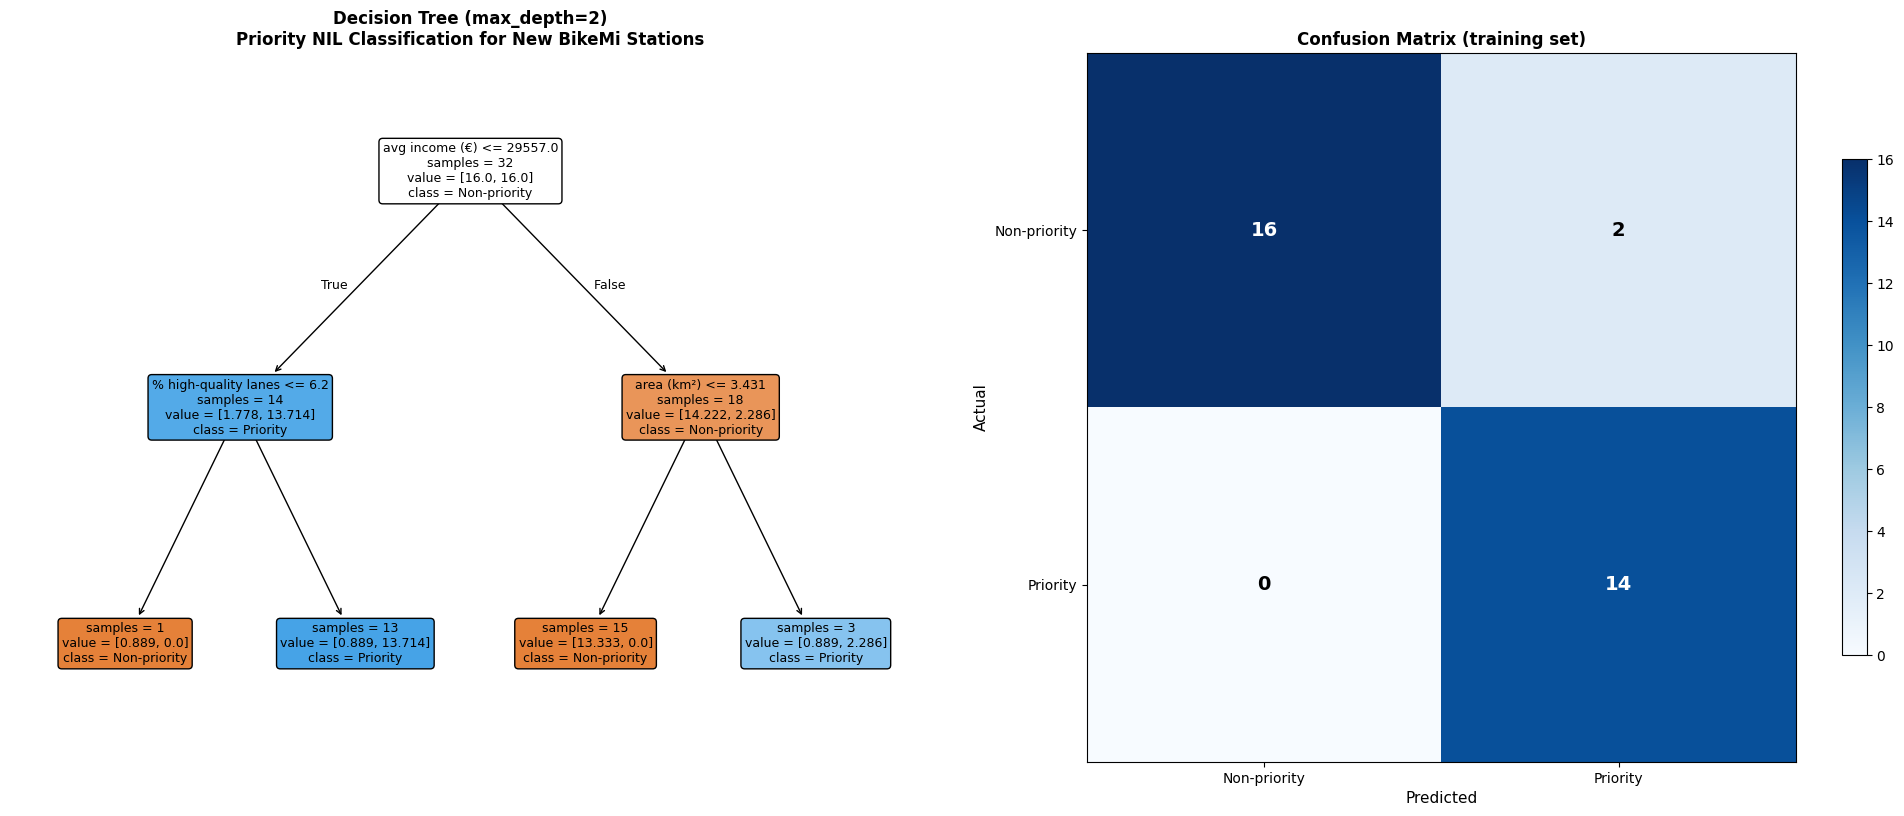

  Saved: 17_decision_tree.png

MAP OF PRIORITY NIL


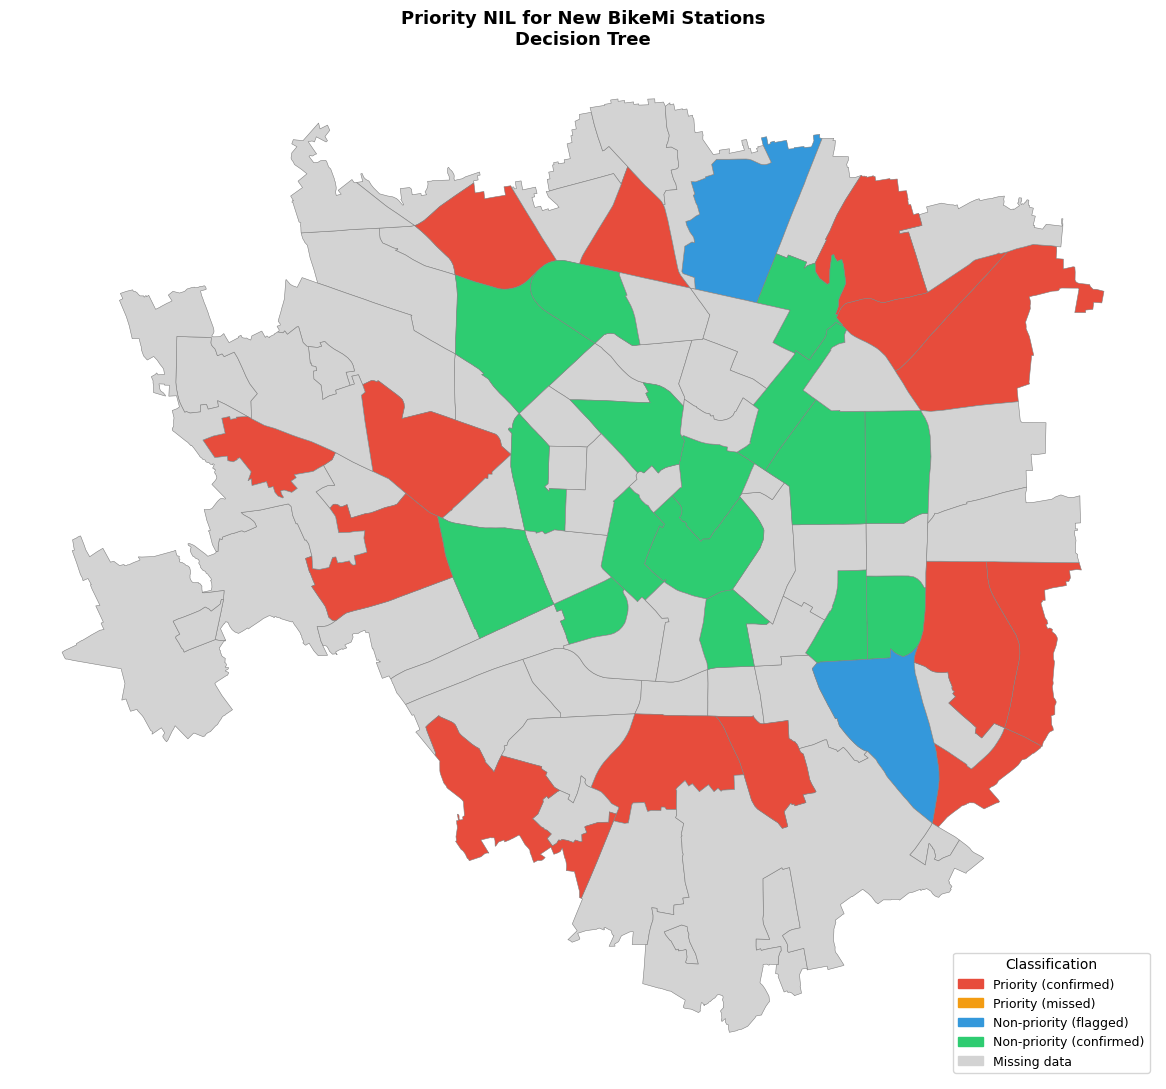

  Saved: 18_priority_nil_map.png

  Classification data saved: nil_priority_classification.csv

SUMMARY STEP 5
  NIL analysed: 32
  Actual priority NIL: 14
  CV accuracy (5-fold): 0.790
  Tree depth: 2

  Predicted priority NIL (map):
                         NIL
      PARCO LAMBRO - CIMIANO
                     S. SIRO
              QUARTO OGGIARO
                      AFFORI
                      PADOVA
           TRIULZO SUPERIORE
PARCO MONLUE' - PONTE LAMBRO
       NIGUARDA - CA' GRANDA
                     STADERA
             LODI - CORVETTO
               QUINTO ROMANO
                    MECENATE
                   RIPAMONTI
                 VIALE MONZA
                FORZE ARMATE
           PARCO DEI NAVIGLI

Outputs generated:
  17_decision_tree.png
  18_priority_nil_map.png
  nil_priority_classification.csv


In [ ]:
#################################################################
# Priority NIL classification for new BikeMi stations
#############################################################

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

print("=" * 55)
print("PRIORITY NIL CLASSIFICATION")
print("=" * 55)

# BINARY TARGET DEFINITION
print("\n" + "=" * 55)
print("BINARY TARGET DEFINITION")
print("=" * 55)

PRIORITY = {
    "Total desert":  1,  # no stations, no bike lanes
    "Lanes without stations": 1,
    "Well served":  0,
    "Stations without lanes": 0,
}

df_cls = nil_socio.copy()
df_cls["priority"] = df_cls["cluster"].map(PRIORITY)

print("\n  Labelling logic:")
for k, v in PRIORITY.items():
    print(f" {k:<30} --> {'priority (1)' if v else 'non-priority (0)'}")

print(f"\n  Target distribution:")
print(df_cls["priority"].value_counts().rename({1: "Priority", 0: "Non-priority"}).to_string())


# FEATURES AND CLEANING
print("\n" + "=" * 55)
print("FEATURES")
print("=" * 55)

FEATURES = [
    "weighted_avg_income", # potential demand (IRPEF income)
    "area_km2",   # NIL size
    "lane_density",  # existing cycling infrastructure
    "pct_high",  # average quality of cycling network
    "pct_covered", # current BikeMi pedestrian coverage
]

df_cls = df_cls.dropna(subset=FEATURES + ["priority"]).copy()
X = df_cls[FEATURES].values
y = df_cls["priority"].values.astype(int)

print(f"  NIL available: {len(df_cls)}")
print(f"  Priority: {y.sum()}  |  Non-priority: {(y==0).sum()}")
print(f"  Features: {FEATURES}")

# DECISION TREE
print("\n" + "=" * 55)
print("DECISION TREE — CROSS VALIDATION")
print("=" * 55)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_depth, best_acc = 3, 0
for depth in [2, 3, 4]:
    clf = DecisionTreeClassifier(max_depth=depth, class_weight="balanced",
                                  random_state=42)
    scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")
    print(f"  max_depth={depth}:  accuracy {scores.mean():.3f} ± {scores.std():.3f}")
    if scores.mean() > best_acc:
        best_acc, best_depth = scores.mean(), depth

print(f"\n  Optimal depth: {best_depth}  (CV accuracy = {best_acc:.3f})")

# fit
clf_final = DecisionTreeClassifier(max_depth=best_depth,
                                    class_weight="balanced",
                                    random_state=42)
clf_final.fit(X, y)

print("\n" + "=" * 55)
print("MODEL RULES (policy interpretation)")
print("=" * 55)

feat_names = [
    "avg income (€)",
    "area (km²)",
    "lane density (km/km²)",
    "% high-quality lanes",
    "pedestrian coverage (%)",
]
rules = export_text(clf_final, feature_names=feat_names)
print(rules)

# TREE VISUALISATION
print("=" * 55)
print("TREE VISUALISATION AND CONFUSION MATRIX")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# tree
plot_tree(
    clf_final,
    feature_names=feat_names,
    class_names=["Non-priority", "Priority"],
    filled=True, rounded=True, fontsize=9, ax=axes[0],
    impurity=False, proportion=False,
)
axes[0].set_title(
    f"Decision Tree (max_depth={best_depth})\n"
    "Priority NIL Classification for New BikeMi Stations",
    fontsize=12, fontweight="bold"
)

# confusion matrix
y_pred_full = clf_final.predict(X)
cm = confusion_matrix(y, y_pred_full)
im = axes[1].imshow(cm, cmap="Blues")
plt.colorbar(im, ax=axes[1], shrink=0.7)
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(["Non-priority", "Priority"], fontsize=10)
axes[1].set_yticklabels(["Non-priority", "Priority"], fontsize=10)
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, str(cm[i, j]), ha="center", va="center",
                     fontsize=14, fontweight="bold",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[1].set_xlabel("Predicted", fontsize=11)
axes[1].set_ylabel("Actual", fontsize=11)
axes[1].set_title("Confusion Matrix (training set)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("17_decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 17_decision_tree.png")

# MAP OF PRIORITY NIL
print("\n" + "=" * 55)
print("MAP OF PRIORITY NIL")
print("=" * 55)

df_cls["priority_pred"] = clf_final.predict(X)

# distinguish TP / FP / FN / TN
def outcome_label(row):
    r, p = row["priority"], row["priority_pred"]
    if r == 1 and p == 1: return "Priority (confirmed)"
    if r == 1 and p == 0: return "Priority (missed)"
    if r == 0 and p == 1: return "Non-priority (flagged)"
    return "Non-priority (confirmed)"

df_cls["outcome"] = df_cls.apply(outcome_label, axis=1)

outcome_colors = {
    "Priority (confirmed)": "#e74c3c",
    "Priority (missed)": "#f39c12",
    "Non-priority (flagged)": "#3498db",
    "Non-priority (confirmed)": "#2ecc71",
}

nil_pred = nil_gdf.merge(
    df_cls[["NIL", "priority_pred", "outcome"]], on="NIL", how="left"
)
nil_pred["color"] = nil_pred["outcome"].map(outcome_colors).fillna("lightgrey")

fig, ax = plt.subplots(figsize=(13, 11))
nil_pred.plot(ax=ax, color=nil_pred["color"], edgecolor="gray", linewidth=0.4)

patch_list = [mpatches.Patch(color=v, label=k) for k, v in outcome_colors.items()]
patch_list.append(mpatches.Patch(color="lightgrey", label="Missing data"))
ax.legend(handles=patch_list, loc="lower right", fontsize=9,
          title="Classification", title_fontsize=10)
ax.set_title(
    "Priority NIL for New BikeMi Stations\n"
    "Decision Tree",
    fontsize=13, fontweight="bold"
)
ax.set_facecolor("#eaf2fb")
ax.axis("off")
plt.tight_layout()
plt.savefig("18_priority_nil_map.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: 18_priority_nil_map.png")

# EXPORT + SUMMARY
df_cls[["NIL", "cluster", "priority", "priority_pred",
        "outcome", "weighted_avg_income", "lane_density",
        "pct_covered"]].to_csv("nil_priority_classification.csv", index=False)
print("\n  Classification data saved: nil_priority_classification.csv")

print("\n" + "=" * 55)
print("SUMMARY STEP 5")
print("=" * 55)
print(f"  NIL analysed: {len(df_cls)}")
print(f"  Actual priority NIL: {y.sum()}")
print(f"  CV accuracy (5-fold): {best_acc:.3f}")
print(f"  Tree depth: {best_depth}")
print(f"\n  Predicted priority NIL (map):")
print(nil_pred[nil_pred["priority_pred"] == 1][["NIL"]].to_string(index=False))
print("\nOutputs generated:")
for f in ["17_decision_tree.png", "18_priority_nil_map.png",
          "nil_priority_classification.csv"]:
    print(f"  {f}")
